# Fine-Tuning Qwen2.5-VL-3B for Graph Property Classification

## Overview

Fine-tune **Qwen2.5-VL-3B-Instruct** using **QLoRA (4-bit)** on the GRAPHTRAILS dataset.

| Component | Choice | Reason |
|-----------|--------|--------|
| **Base Model** | Qwen2.5-VL-3B-Instruct | Best VL model that fits Kaggle T4x2 for training |
| **Method** | QLoRA (4-bit NF4) | 3B model → ~2GB weights in 4-bit, LoRA adds ~50MB trainable |
| **Task** | Binary VQA per property | Image + visual certificate prompt → YES/NO |
| **Dataset** | 4,800 images (8 properties × 3 classes × 200) | Train/Val/Test: 70/15/15 |

### Pipeline
1. Install dependencies
2. Load model in 4-bit with LoRA adapters
3. Prepare dataset as conversations (image + certificate prompt → YES/NO)
4. Train with custom collate + gradient checkpointing
5. Evaluate on test set (Exp1: s_no, Exp2: d_no)
6. Compare with zero-shot baseline & fine-tuned vision models

---
**Kaggle**: GPU T4 x2, ~30 GB RAM, ~15 GB VRAM per GPU

In [1]:
# ============================================================================
# STEP 1: Install Dependencies
# ============================================================================
# IMPORTANT: Run this cell first, then restart kernel if needed.

# !pip install -q git+https://github.com/huggingface/transformers.git
# !pip install -q accelerate bitsandbytes peft trl
# !pip install -q "qwen-vl-utils>=0.0.14"
# !pip install -q pillow scikit-learn matplotlib seaborn tqdm

print("✓ All dependencies installed")

✓ All dependencies installed


In [2]:
# ============================================================================
# STEP 2: Imports
# ============================================================================

import os
import json
import random
import copy
import time
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
from typing import Dict, List, Tuple, Optional
from collections import Counter, defaultdict
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoModelForImageTextToText,
    AutoProcessor,
    BitsAndBytesConfig,
    TrainingArguments,
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, TaskType

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

import matplotlib.pyplot as plt
import seaborn as sns
import torchvision.transforms.functional as TF
from functools import partial
from sklearn.model_selection import train_test_split

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch: 2.6.0+cu124
CUDA available: True
GPU: NVIDIA GeForce RTX 4070 Ti


In [ ]:
# ============================================================================
# STEP 3: Configuration
# ============================================================================

class Config:
    # ── Model ─────────────────────────────────────────────────────────────
    MODEL_NAME = 'Qwen/Qwen2.5-VL-3B-Instruct'

    # ── Dataset ───────────────────────────────────────────────────────────
    DATASET_ROOT       = 'data_generator/graphtrails_dataset'
    ALL_PROPERTIES     = [
        'cut_vertex', 'connectivity', 'bipartite', 'planarity',
        'outer_planarity', 'hamiltonian', 'k_colorability', 'completeness'
    ]
    # Full dataset by default. Set an int only for fast debugging.
    SAMPLES_PER_CLASS  = None # Set `None` for full dataset 

    # ── Split ratios ──────────────────────────────────────────────────────
    TRAIN_RATIO = 0.70
    VAL_RATIO   = 0.15
    TEST_RATIO  = 0.15
    SEED        = 42

    # ── Training ─────────────────────────────────────────────────────────
    NUM_EPOCHS        = 3
    BATCH_SIZE        = 1
    GRAD_ACCUM_STEPS  = 8     # Effective batch = 8
    LEARNING_RATE     = 2e-4
    WEIGHT_DECAY      = 0.01
    WARMUP_RATIO      = 0.05
    MAX_SEQ_LENGTH    = 2048

    # Early stopping (MLLM-applicable parity with vision rigor)
    EARLY_STOPPING = True
    EARLY_STOPPING_PATIENCE = 2
    EARLY_STOPPING_MIN_DELTA = 1e-4

    # ── QLoRA ─────────────────────────────────────────────────────────────
    USE_4BIT            = True
    LORA_R              = 16
    LORA_ALPHA          = 32
    LORA_DROPOUT        = 0.05
    LORA_TARGET_MODULES = [
        'q_proj', 'k_proj', 'v_proj', 'o_proj',
        'gate_proj', 'up_proj', 'down_proj'
    ]

    # ── Image ─────────────────────────────────────────────────────────────
    MIN_PIXELS = 4   * 28 * 28
    MAX_PIXELS = 400 * 28 * 28
    IMG_SIZE = 400

    # ── Image Augmentation (matching vision_model_finetune.ipynb exactly) ────
    USE_AUGMENTATION = True    # Enable/disable training augmentations
    USE_PHOTOMETRIC_AUGMENTATION = True  # Enable ColorJitter etc.
    AUG_ROTATION_DEGREES = 180
    AUG_HFLIP_PROB = 0.5
    AUG_VFLIP_PROB = 0.3
    AUG_BRIGHTNESS = 0.2
    AUG_CONTRAST = 0.2
    AUG_SATURATION = 0.1
    AUG_HUE = 0.05

    # ── Shared Augmentation Bank (Train + optional TTA) ─────────────────
    USE_TTA = False
    EVAL_COMPARE_BASELINE_AND_TTA = False  # True = run eval twice (slower)

    # Common transforms applied to ALL samples
    AUG_COMMON_TRANSFORMS = ['original', 'color_invert_full', 'color_invert_channel_rot']

    # Geometric transforms: per property × per layout group
    AUG_GEOMETRIC_TRANSFORMS = {
        'cut_vertex':      {'same': ['vflip', 'rotate_n20', 'rotate_p20'],
                            'diff': ['vflip', 'rotate_n90', 'rotate_p90']},
        'connectivity':    {'same': ['vflip', 'rotate_n90', 'rotate_p90'],
                            'diff': ['vflip', 'rotate_n90', 'rotate_p90']},
        'bipartite':       {'same': ['flip_y_eq_x', 'rotate_n20', 'rotate_p20'],
                            'diff': ['flip_y_eq_neg_x', 'rotate_n20', 'rotate_p20']},
        'planarity':       {'same': ['vflip', 'rotate_n20', 'rotate_p20'],
                            'diff': ['vflip', 'rotate_n90', 'rotate_p90']},
        'outer_planarity': {'same': ['vflip', 'rotate_n90', 'rotate_p90'],
                            'diff': ['vflip', 'rotate_n90', 'rotate_p90']},
        'hamiltonian':     {'same': ['vflip', 'rotate_n90', 'rotate_p90'],
                            'diff': ['vflip', 'rotate_n90', 'rotate_p90']},
        'k_colorability':  {'same': ['flip_y_eq_x', 'rotate_n20', 'rotate_p20'],
                            'diff': ['flip_y_eq_neg_x', 'rotate_n20', 'rotate_p20']},
        'completeness':    {'same': ['flip_y_eq_x', 'rotate_n20', 'rotate_p20'],
                            'diff': ['flip_y_eq_x', 'rotate_n20', 'rotate_p20']},
    }

    # Convenience alias
    AUG_TRANSFORMS = AUG_COMMON_TRANSFORMS

    # ── Reasoning Texts ───────────────────────────────────────────────────
    USE_REASONING_TEXTS = True  # Use generated reasoning texts from dataset

    # ── Two separate pipeline checkpoints & results ───────────────────────
    CHECKPOINT_DIR_SNO = './mllm_checkpoints/pipeline_sno'   # Same layout
    CHECKPOINT_DIR_DNO = './mllm_checkpoints/pipeline_dno'   # Different layout
    RESULTS_DIR        = './mllm_results'


config = Config()
os.makedirs(config.CHECKPOINT_DIR_SNO, exist_ok=True)
os.makedirs(config.CHECKPOINT_DIR_DNO, exist_ok=True)
os.makedirs(config.RESULTS_DIR, exist_ok=True)

print(f"Model:              {config.MODEL_NAME}")
print(f"Dataset:            {config.DATASET_ROOT}")
print(f"Epochs:             {config.NUM_EPOCHS}")
print(f"USE_4BIT:           {config.USE_4BIT}")
print(f"USE_AUGMENTATION:   {config.USE_AUGMENTATION}")
print(f"USE_REASONING:      {config.USE_REASONING_TEXTS}")
print(f"USE_TTA:            {config.USE_TTA}")
print(f"EARLY_STOPPING:     {config.EARLY_STOPPING}")
print(f"\nCheckpoints:")
print(f"  Pipeline 1 (s_no): {config.CHECKPOINT_DIR_SNO}")
print(f"  Pipeline 2 (d_no): {config.CHECKPOINT_DIR_DNO}")

Model:              Qwen/Qwen2.5-VL-3B-Instruct
Dataset:            data_generator/graphtrails_dataset
Epochs:             3
USE_4BIT:           True
USE_AUGMENTATION:   True
USE_REASONING:      True
USE_TTA:            False
EARLY_STOPPING:     True

Checkpoints:
  Pipeline 1 (s_no): ./mllm_checkpoints/pipeline_sno
  Pipeline 2 (d_no): ./mllm_checkpoints/pipeline_dno


## Step 4: Visual Certificate Definitions

Same visual certificates used in zero-shot evaluation.  
During fine-tuning, the model learns to **interpret these patterns** rather than just follow instructions.

In [4]:
# ============================================================================
# STEP 5: Define Visual Certificate Descriptions (3-CLASS: yes, s_no, d_no)
# ============================================================================
# Based on Plan.md - correct visual strategies for each class

VISUAL_CERTIFICATES = {
    'cut_vertex': {
        'name': 'Cut Vertex',
        'yes': 'YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.',
        's_no': 'NO if: Same bridge-like layout, but dense clusters have edges between them (2-connected, no cut vertex).',
        'd_no': 'NO if: Ear decomposition (flower pattern) with ears spreading around central path, proving 2-connectivity.'
    },
    
    'connectivity': {
        'name': 'Graph Connectivity',
        'yes': 'YES if: BFS tree on concentric circles with BOLD spanning tree edges in a single component graph.',
        's_no': 'NO if: BFS tree on concentric circles but BOLD spanning tree only covers maximum component (not all components).',
        'd_no': 'NO if: Spatially SEPARATED clusters with clear visible gaps between them, showing disconnection.'
    },
    
    'bipartite': {
        'name': 'Bipartite Graph',
        'yes': 'YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.',
        's_no': 'NO if: Matrix sorted into 2 blocks on diagonal, but diagonal blocks HAVE edges inside (colored cells in diagonal blocks, not all empty).',
        'd_no': 'NO if: Odd cycle HIGHLIGHTED in top-left block. Cycle nodes connected sequentially forming odd-length closed path.'
    },
    
    'planarity': {
        'name': 'Planarity',
        'yes': 'YES if: Planar embedding with ZERO edge crossings. Clean spread layout with no lines intersecting.',
        's_no': 'NO if: Same spread layout style as YES, but some edges visibly CROSS each other (non-planar edges).',
        'd_no': 'NO if: BOLD edges highlight K₅ (pentagon with all diagonals) or K₃,₃ (bipartite 3+3) minor proving non-planarity.'
    },
    
    'outer_planarity': {
        'name': 'Outer-Planarity',
        'yes': 'YES if: Outer-planar embedding with ALL vertices on outer face and ZERO edge crossings.',
        's_no': 'NO if: Outer-planar style layout but some edges visibly CROSS each other.',
        'd_no': 'NO if: BOLD edges highlight K₄ (4 nodes fully connected) or K₂,₃ (2+3 bipartite) minor proving non-outer-planarity.'
    },
    
    'hamiltonian': {
        'name': 'Hamiltonian Cycle',
        'yes': 'YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.',
        's_no': 'NO if: Longest cycle on outer circle (LOOKS like Hamiltonian) but some nodes are INSIDE the cycle.',
        'd_no': 'NO if: Cut-set (S) shown as BOLD highlighted nodes at center. k(G-S) > |S| proving no Hamiltonian cycle.'
    },
    
    'k_colorability': {
        'name': '4-Colorability',
        'yes': 'YES if: Matrix with ≤4 EMPTY diagonal blocks. Each block = one color class (independent set). Every diagonal block is completely empty.',
        's_no': 'NO if: Matrix with >4 EMPTY diagonal blocks (5-8 blocks visible on diagonal), needs more than 4 colors.',
        'd_no': 'NO if: Matrix with highlighted K₅/K₆/K₇/K₈ clique (BOLD highlighted edges forming complete subgraph in top-left block). Except diagonal, every cell in top-left block is filled, showing large clique.'
    },
    
    'completeness': {
        'name': 'Graph Completeness',
        'yes': 'YES if: Full adjacency matrix - ALL cells filled, all edges present between every pair of nodes. Only diagonal cells are empty (no self-loops).',
        's_no': 'NO if: There are some missing edges (empty cells outside diagonal) in the adjacency matrix, showing it is not complete.',
        'd_no': 'NO if: Nodes are sorted by degree (most connected to least). Matrix shows density gradient: dense/filled top-left region fading to sparse/empty bottom-right, proving that not all node pairs are connected.'
    }
}

print(f"✓ Loaded {len(VISUAL_CERTIFICATES)} visual certificates (yes/s_no/d_no)")
for prop, cert in VISUAL_CERTIFICATES.items():
    print(f"  - {prop}: {cert['name']}")

✓ Loaded 8 visual certificates (yes/s_no/d_no)
  - cut_vertex: Cut Vertex
  - connectivity: Graph Connectivity
  - bipartite: Bipartite Graph
  - planarity: Planarity
  - outer_planarity: Outer-Planarity
  - hamiltonian: Hamiltonian Cycle
  - k_colorability: 4-Colorability
  - completeness: Graph Completeness


In [5]:
# ============================================================================
# STEP 5.5: Load Dataset & Split into TWO Separate Pipelines
# ============================================================================


def _load_reasoning_map(dataset_root: str, property_name: str) -> dict:
    """
    Load reasoning map from:
      1) dataset_root/reasoning_texts.json (global map), and/or
      2) dataset_root/<property>/reasoning_texts.json (property map).

    Property file entries override global entries if keys overlap.
    """
    merged = {}

    global_path = os.path.join(dataset_root, 'reasoning_texts.json')
    prop_path = os.path.join(dataset_root, property_name, 'reasoning_texts.json')

    for p in [global_path, prop_path]:
        if os.path.exists(p):
            try:
                with open(p, 'r', encoding='utf-8') as f:
                    data = json.load(f)
                if isinstance(data, dict):
                    merged.update(data)
            except Exception as e:
                print(f"  ⚠️ Failed to load reasoning file: {p} | {e}")

    return merged


def load_all_samples(dataset_root, properties, max_per_class=None, seed=42, use_reasoning=True):
    """
    Load PNG samples and optional reasoning texts.

    Args:
        max_per_class:
            - None -> use full dataset
            - int  -> cap each (property, sample_type) bucket
    """
    samples = []
    rng = random.Random(seed)

    reasoning_stats = {
        'total_samples': 0,
        'reasoning_found': 0,
        'per_property': defaultdict(lambda: {'samples': 0, 'reasoning_found': 0}),
        'source_found': {'global': False, 'property_files': 0}
    }

    global_reasoning_path = os.path.join(dataset_root, 'reasoning_texts.json')
    if os.path.exists(global_reasoning_path):
        reasoning_stats['source_found']['global'] = True

    for prop in properties:
        prop_dir = os.path.join(dataset_root, prop)
        if not os.path.exists(prop_dir):
            print(f"  ⚠️ Missing: {prop_dir}")
            continue

        prop_reasoning = _load_reasoning_map(dataset_root, prop) if use_reasoning else {}
        if os.path.exists(os.path.join(prop_dir, 'reasoning_texts.json')):
            reasoning_stats['source_found']['property_files'] += 1

        for sample_type, label in [('yes', 1), ('s_no', 0), ('d_no', 0)]:
            type_dir = os.path.join(prop_dir, sample_type)
            if not os.path.exists(type_dir):
                continue

            files = sorted(f for f in os.listdir(type_dir) if f.endswith('.png'))
            if max_per_class is not None and len(files) > max_per_class:
                files = rng.sample(files, max_per_class)
                files.sort()

            for fname in files:
                reasoning = None
                if use_reasoning and prop_reasoning:
                    # Try robust key matching
                    stem = os.path.splitext(fname)[0]
                    reasoning = (
                        prop_reasoning.get(fname)
                        or prop_reasoning.get(stem)
                        or prop_reasoning.get(f"{stem}.png")
                    )

                sample = {
                    'image_path':  os.path.join(type_dir, fname),
                    'property':    prop,
                    'label':       label,
                    'sample_type': sample_type,
                    'answer':      'YES' if label == 1 else 'NO',
                }
                if reasoning:
                    sample['reasoning'] = reasoning

                samples.append(sample)

                reasoning_stats['total_samples'] += 1
                reasoning_stats['per_property'][prop]['samples'] += 1
                if reasoning:
                    reasoning_stats['reasoning_found'] += 1
                    reasoning_stats['per_property'][prop]['reasoning_found'] += 1

    return samples, reasoning_stats


def pipeline_split(samples, config):
    """Stratified train/val/test split for a given sample list."""
    strat = [f"{s['property']}_{s['sample_type']}" for s in samples]
    train_, temp_, _, temp_keys = train_test_split(
        samples, strat,
        test_size=(config.VAL_RATIO + config.TEST_RATIO),
        stratify=strat, random_state=config.SEED
    )
    val_, test_ = train_test_split(
        temp_,
        test_size=config.TEST_RATIO / (config.VAL_RATIO + config.TEST_RATIO),
        stratify=temp_keys, random_state=config.SEED
    )
    return train_, val_, test_


# Load all samples (FULL dataset by default when cap=None)
all_samples, reasoning_stats = load_all_samples(
    config.DATASET_ROOT,
    config.ALL_PROPERTIES,
    max_per_class=config.SAMPLES_PER_CLASS,
    seed=config.SEED,
    use_reasoning=config.USE_REASONING_TEXTS,
)

print(f"Total samples loaded:  {len(all_samples)}  (cap={config.SAMPLES_PER_CLASS})")
print(f"  Per type: {dict(Counter(s['sample_type'] for s in all_samples))}")

# Reasoning coverage diagnostics
if config.USE_REASONING_TEXTS:
    total = reasoning_stats['total_samples']
    found = reasoning_stats['reasoning_found']
    pct = (100.0 * found / total) if total else 0.0
    print("\nReasoning text coverage:")
    print(f"  Global reasoning file found: {reasoning_stats['source_found']['global']}")
    print(f"  Property reasoning files found: {reasoning_stats['source_found']['property_files']}")
    print(f"  Attached reasoning: {found}/{total} ({pct:.2f}%)")

    if found == 0:
        print("  ⚠️ No reasoning texts attached. Training will use generic fallback responses.")

    for prop in config.ALL_PROPERTIES:
        p = reasoning_stats['per_property'][prop]
        if p['samples'] == 0:
            continue
        ppct = 100.0 * p['reasoning_found'] / p['samples']
        print(f"    - {prop:<16} {p['reasoning_found']:>5}/{p['samples']:<5} ({ppct:>6.2f}%)")

# ── Pipeline 1: Same Layout  (yes + s_no only) ───────────────────────
sno_samples = [s for s in all_samples if s['sample_type'] in ['yes', 's_no']]
sno_train, sno_val, sno_test = pipeline_split(sno_samples, config) #TODO

# ── Pipeline 2: Different Layout (yes + d_no only) ───────────────────
dno_samples = [s for s in all_samples if s['sample_type'] in ['yes', 'd_no']]
dno_train, dno_val, dno_test = pipeline_split(dno_samples, config) #TODO

print(f"\n{'Pipeline':<30} {'Train':>8} {'Val':>6} {'Test':>6} {'Total':>7}")
print("-" * 60)
print(f"{'Pipeline 1 — Same Layout (s_no)':<30} {len(sno_train):>8} {len(sno_val):>6} {len(sno_test):>6} {len(sno_samples):>7}")
print(f"{'Pipeline 2 — Diff Layout (d_no)':<30} {len(dno_train):>8} {len(dno_val):>6} {len(dno_test):>6} {len(dno_samples):>7}")
print(f"\n✓ Each pipeline has its own independent train/val/test split.")

Total samples loaded:  24000  (cap=None)
  Per type: {'yes': 8000, 's_no': 8000, 'd_no': 8000}

Reasoning text coverage:
  Global reasoning file found: True
  Property reasoning files found: 0
  Attached reasoning: 24000/24000 (100.00%)
    - cut_vertex        3000/3000  (100.00%)
    - connectivity      3000/3000  (100.00%)
    - bipartite         3000/3000  (100.00%)
    - planarity         3000/3000  (100.00%)
    - outer_planarity   3000/3000  (100.00%)
    - hamiltonian       3000/3000  (100.00%)
    - k_colorability    3000/3000  (100.00%)
    - completeness      3000/3000  (100.00%)

Pipeline                          Train    Val   Test   Total
------------------------------------------------------------
Pipeline 1 — Same Layout (s_no)    11200   2400   2400   16000
Pipeline 2 — Diff Layout (d_no)    11200   2400   2400   16000

✓ Each pipeline has its own independent train/val/test split.


In [6]:
# ============================================================================
# STEP 6: Build Conversation Format for Training
# ============================================================================

def build_prompt(property_name: str, sample_type: str) -> str:
    """
    Build the user prompt for a given property.
    Uses the appropriate NO rule based on sample_type:
    - For 'yes' and 's_no' samples → use s_no rule (same-layout context)
    - For 'd_no' samples → use d_no rule (different-layout context)
    """
    cert = VISUAL_CERTIFICATES[property_name]
    
    # Determine which NO rule to use based on sample type
    if sample_type == 'd_no':
        no_rule = cert['d_no']
    else:
        no_rule = cert['s_no']
    
    return (
        f"Property: {cert['name']}\n\n"
        f"Rules:\n"
        f"- {cert['yes']}\n"
        f"- {no_rule}\n\n"
        f"Question: Does this graph have {cert['name']}? Answer YES or NO with detailed reasoning.\n\n"
        f"Format: YES/NO: [detailed reasoning explaining your observation]"
    )


def build_answer(label: int, property_name: str, sample_type: str, reasoning: str = None) -> str:
    """
    Build the expected assistant answer.
    Uses reasoning text from dataset if available, otherwise generates a generic response.
    
    Args:
        label: 1 for YES, 0 for NO
        property_name: Name of the graph property
        sample_type: 'yes', 's_no', or 'd_no'
        reasoning: Pre-generated reasoning text from dataset (if available)
    """
    cert = VISUAL_CERTIFICATES[property_name]
    
    # Use reasoning text if available (from updated dataset)
    if reasoning and config.USE_REASONING_TEXTS:
        if label == 1:
            return f"YES: {reasoning}"
        else:
            return f"NO: {reasoning}"
    
    # Fallback to generic responses
    if label == 1:
        return f"YES: The graph has {cert['name']}. The visual pattern matches the positive indicator."
    else:
        if sample_type == 'd_no':
            return f"NO: The graph does not have {cert['name']}. The visual certificate proves the negative case."
        else:
            return f"NO: The graph does not have {cert['name']}. Despite similar layout, the pattern indicates negative."


def sample_to_conversation(sample: dict, prompt_type: str = None) -> dict:
    """
    Convert a dataset sample to Qwen VL conversation format.
    
    prompt_type: If specified, overrides sample['sample_type'] for determining
                 which NO rule to show in prompt. Use 's_no' for Pipeline 1,
                 'd_no' for Pipeline 2. This ensures training/eval consistency.
    Returns: {'messages': [...], 'image_path': str}
    """
    # Use explicit prompt_type if provided, otherwise fall back to sample's type
    effective_type = prompt_type if prompt_type else sample['sample_type']
    # For 'yes' samples, use the pipeline's prompt_type instead
    if sample['sample_type'] == 'yes' and prompt_type:
        effective_type = prompt_type
    
    prompt = build_prompt(sample['property'], effective_type)
    
    # Get reasoning text from sample (may be None)
    reasoning = sample.get('reasoning', None)
    answer = build_answer(sample['label'], sample['property'], effective_type, reasoning)
    
    messages = [
        {
            'role': 'user',
            'content': [
                {'type': 'image', 'image': sample['image_path']},
                {'type': 'text', 'text': prompt}
            ]
        },
        {
            'role': 'assistant',
            'content': [
                {'type': 'text', 'text': answer}
            ]
        }
    ]
    
    return {'messages': messages, 'image_path': sample['image_path']}


# Quick test using Pipeline 1 samples
test_conv = sample_to_conversation(sno_train[0], prompt_type='s_no')
print("Sample conversation (Pipeline 1 - s_no):")
print(f"  User prompt (text part):")
for c in test_conv['messages'][0]['content']:
    if c['type'] == 'text':
        print(f"    {c['text'][:200]}...")
print(f"  Assistant answer:")
print(f"    {test_conv['messages'][1]['content'][0]['text'][:200]}...")
print(f"  Image: {test_conv['image_path']}\n\n")

# Quick test using Pipeline 2 samples
test_conv = sample_to_conversation(dno_train[0], prompt_type='d_no')
print("Sample conversation (Pipeline 2 - d_no):")
print(f"  User prompt (text part):")
for c in test_conv['messages'][0]['content']:
    if c['type'] == 'text':
        print(f"    {c['text'][:200]}...")
print(f"  Assistant answer:")
print(f"    {test_conv['messages'][1]['content'][0]['text'][:200]}...")
print(f"  Image: {test_conv['image_path']}")

Sample conversation (Pipeline 1 - s_no):
  User prompt (text part):
    Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.
- NO if: Matrix sorted into 2 bl...
  Assistant answer:
    NO: Not bipartite despite the 2-block structure. Intra-partition edges (visible as colored cells in diagonal blocks) prove nodes cannot be 2-colored without adjacent same-color nodes....
  Image: data_generator/graphtrails_dataset\bipartite\s_no\bipartite_s_no_618.png


Sample conversation (Pipeline 2 - d_no):
  User prompt (text part):
    Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.
- NO if: Odd cycle HIGHLIGHTED i...
  Assistant answer:
    NO: An odd-length cycle (7 nodes) is highlighted. This cycle cannot be 2-colored since alternating colors return to the start wit

In [7]:
# ============================================================================
# STEP 7: Helper — Load Fresh Base Model + Processor
# ============================================================================

def load_base_model(config):
    """Load a fresh Qwen2.5-VL model (no LoRA). Returns (model, processor)."""
    print(f"Loading base model: {config.MODEL_NAME} ...")

    try:
        import bitsandbytes as bnb
        bnb_available = True
        print(f"  bitsandbytes {bnb.__version__} available — using 4-bit NF4")
    except ImportError:
        bnb_available = False
        print("  ⚠️  bitsandbytes unavailable — using fp16")

    if config.USE_4BIT and bnb_available:
        bnb_cfg = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type='nf4',
            bnb_4bit_compute_dtype=torch.bfloat16,
            bnb_4bit_use_double_quant=True,
        )
        mdl = AutoModelForImageTextToText.from_pretrained(
            config.MODEL_NAME,
            quantization_config=bnb_cfg,
            device_map='auto',
            trust_remote_code=True,
            attn_implementation='eager',
            torch_dtype=torch.bfloat16,
        )
        print("  ✓ Model loaded in 4-bit QLoRA")
    else:
        dtype = torch.bfloat16 if (torch.cuda.is_available() and
                                    torch.cuda.is_bf16_supported()) else torch.float16
        mdl = AutoModelForImageTextToText.from_pretrained(
            config.MODEL_NAME,
            device_map='auto',
            trust_remote_code=True,
            attn_implementation='eager',
            torch_dtype=dtype,
        )
        print(f"  ✓ Model loaded in {dtype}")

    proc = AutoProcessor.from_pretrained(
        config.MODEL_NAME,
        trust_remote_code=True,
        min_pixels=config.MIN_PIXELS,
        max_pixels=config.MAX_PIXELS,
    )

    if torch.cuda.is_available():
        print(f"  GPU memory after load: {torch.cuda.memory_allocated()/1e9:.2f} GB")

    return mdl, proc


print("✓ load_base_model() defined")


✓ load_base_model() defined


In [8]:
# ============================================================================
# STEP 8: Helper  Apply LoRA Adapters to a Base Model
# ============================================================================

def apply_lora_adapters(mdl, config):
    """Wrap base model with QLoRA. Returns peft model."""
    try:
        import bitsandbytes as _bnb
        bnb_available = True
    except ImportError:
        bnb_available = False

    if config.USE_4BIT and bnb_available:
        mdl = prepare_model_for_kbit_training(mdl, use_gradient_checkpointing=True)
    else:
        mdl.enable_input_require_grads()
        mdl.gradient_checkpointing_enable()

    lora_cfg = LoraConfig(
        r=config.LORA_R,
        lora_alpha=config.LORA_ALPHA,
        lora_dropout=config.LORA_DROPOUT,
        target_modules=config.LORA_TARGET_MODULES,
        bias='none',
        task_type=TaskType.CAUSAL_LM,
    )
    mdl = get_peft_model(mdl, lora_cfg)

    trainable = sum(p.numel() for p in mdl.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in mdl.parameters())
    print(f"  LoRA applied  trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)")
    return mdl


print("✓ apply_lora_adapters() defined")


✓ apply_lora_adapters() defined


In [ ]:
# ============================================================================
# STEP 9: Helper  Dataset Class, Collate Function, DataLoader Factory
# ============================================================================
from functools import partial
import torchvision.transforms as T
import torchvision.transforms.functional as TF

# ============================================================================
# IMAGE AUGMENTATION FOR MLLM TRAINING (similar to vision_model_finetune.ipynb)
# ============================================================================

import torchvision.transforms as transforms

import random as _random

class TrainAugmentation:
    """Property-aware image augmentation for training.
    
    Uses the same shared per-property, per-layout transform config,
    but randomly picks one transform per sample during training.
    This ensures training augmentation is semantically valid for each
    graph property type.
    """
    def __init__(self, cfg):
        self.enabled = getattr(cfg, 'USE_AUGMENTATION', False)
        self.img_size = getattr(cfg, 'IMG_SIZE', 400)
        self.common_transforms = getattr(cfg, 'AUG_COMMON_TRANSFORMS', ['original'])
        self.use_photometric = getattr(cfg, 'USE_PHOTOMETRIC_AUGMENTATION', True)
        self.photometric = transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1)
        self.geometric_transforms = getattr(cfg, 'AUG_GEOMETRIC_TRANSFORMS', {})
        
        self.val_transform = transforms.Compose([
            transforms.Resize((cfg.IMG_SIZE, cfg.IMG_SIZE))
        ])
    
    def get_transforms_for_sample(self, property_name: str, layout_key: str) -> list:
        """Return list of valid transform names for a (property, layout) pair."""
        if layout_key in ('s_no', 'yes'):
            geo_key = 'same'
        elif layout_key == 'd_no':
            geo_key = 'diff'
        elif layout_key in ('same', 'diff'):
            geo_key = layout_key
        else:
            geo_key = 'same'
        
        geo = self.geometric_transforms.get(property_name, {}).get(geo_key, [])
        return list(self.common_transforms) + list(geo)
    
    def apply_single_transform(self, image, transform_name: str):
        """Apply a named transform to a PIL image. Returns a PIL image."""
        image = image.resize((self.img_size, self.img_size))
        
        if transform_name == 'original':
            return image.copy()
        
        # Color transforms
        if transform_name == 'color_invert_full':
            from PIL import ImageOps
            return ImageOps.invert(image.convert('RGB'))
        
        if transform_name == 'color_invert_channel_rot':
            import numpy as np
            arr = np.array(image)
            rotated = np.stack([arr[:, :, 2], arr[:, :, 0], arr[:, :, 1]], axis=-1)
            return Image.fromarray(rotated)
        
        # Geometric transforms
        if transform_name == 'hflip':
            return TF.hflip(image)
        if transform_name == 'vflip':
            return TF.vflip(image)
        if transform_name == 'rotate_n20':
            return TF.rotate(image, -20, fill=255)
        if transform_name == 'rotate_p20':
            return TF.rotate(image, 20, fill=255)
        if transform_name == 'rotate_n90':
            return TF.rotate(image, -90, fill=255)
        if transform_name == 'rotate_p90':
            return TF.rotate(image, 90, fill=255)
        if transform_name == 'flip_y_eq_x':
            return image.transpose(Image.TRANSPOSE)
        if transform_name == 'flip_y_eq_neg_x':
            return image.transpose(Image.TRANSVERSE)
        
        # Unknown → return resized original
        return image.copy()
    
    def __call__(self, image, property_name=None, layout_key=None, force_val=False):
        """Apply a random property-aware transform during training.
        
        Args:
            image: PIL image
            property_name: e.g. 'bipartite', 'hamiltonian', etc.
            layout_key: e.g. 's_no', 'd_no', 'yes'
            force_val: if True, just resize (no augmentation)
        """
        if not self.enabled or force_val:
            return self.val_transform(image)
        
        if property_name and layout_key:
            valid_transforms = self.get_transforms_for_sample(property_name, layout_key)
            chosen = _random.choice(valid_transforms)
            return self.apply_single_transform(image, chosen)
        else:
            # Fallback: just resize if no property info available
            return self.val_transform(image)


# ============================================================================
# Create global augmentation object
if config.USE_AUGMENTATION:
    train_augmentation = TrainAugmentation(config)
    print(f"✓ TrainAugmentation defined (matching vision_model_finetune.ipynb)")
    print(f"  Enabled: {config.USE_AUGMENTATION}")


class GraphVLDataset(Dataset):
    def __init__(self, samples: List[dict], augment: bool = False):
        self.samples = samples
        self.augment = augment
        self.augmentation = train_augmentation if augment else None
        
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        sample = self.samples[idx].copy()  # Copy to avoid modifying original
        sample['_augment'] = self.augment  # Flag for collate function
        return sample


def train_collate_fn(batch, prompt_type: str = None, augment: bool = False):
    """
    Collate: converts sample dicts → tokenised (input_ids, attention_mask,
    labels, pixel_values, image_grid_thw). Labels are masked for user tokens.
    
    prompt_type: 's_no' for Pipeline 1, 'd_no' for Pipeline 2.
                 Ensures consistent prompts for all samples in the pipeline.
    augment: If True, apply augmentations to training images.
    """
    all_input_ids, all_attention_mask, all_labels = [], [], []
    all_pixel_values, all_image_grid_thw = [], []

    for sample in batch:
        # Pass prompt_type to ensure consistent prompts within the pipeline
        conv     = sample_to_conversation(sample, prompt_type=prompt_type)
        messages = conv['messages']
        
        # Load and optionally augment image
        image = Image.open(sample['image_path']).convert('RGB')
        should_augment = augment or sample.get('_augment', False)
        if should_augment and train_augmentation.enabled:
            image = train_augmentation(image, property_name=sample.get('property'), layout_key=sample.get('sample_type'))

        full_text   = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
        full_inputs = processor(
            text=[full_text], images=[image],
            return_tensors='pt', padding=False,
            max_length=config.MAX_SEQ_LENGTH, truncation=True,
        )

        input_ids      = full_inputs['input_ids'].squeeze(0)
        attention_mask = full_inputs['attention_mask'].squeeze(0)

        # Find where assistant response starts
        user_text   = processor.apply_chat_template([messages[0]], tokenize=False, add_generation_prompt=True)
        user_inputs = processor(
            text=[user_text], images=[image],
            return_tensors='pt', padding=False,
            max_length=config.MAX_SEQ_LENGTH, truncation=True,
        )
        user_len = user_inputs['input_ids'].shape[1]

        labels = input_ids.clone()
        labels[:user_len] = -100  # mask user tokens

        all_input_ids.append(input_ids)
        all_attention_mask.append(attention_mask)
        all_labels.append(labels)

        if 'pixel_values' in full_inputs:
            all_pixel_values.append(full_inputs['pixel_values'].squeeze(0))
        if 'image_grid_thw' in full_inputs:
            # Keep 2-D (n_images, 3)  do NOT squeeze
            all_image_grid_thw.append(full_inputs['image_grid_thw'])

    # Pad sequences to same length
    max_len = max(ids.shape[0] for ids in all_input_ids)
    pad_id  = processor.tokenizer.pad_token_id or 0
    padded_ids, padded_mask, padded_labs = [], [], []
    for ids, mask, labs in zip(all_input_ids, all_attention_mask, all_labels):
        p = max_len - ids.shape[0]
        padded_ids.append( torch.cat([ids,  torch.full((p,), pad_id, dtype=ids.dtype)]))
        padded_mask.append(torch.cat([mask, torch.zeros(p, dtype=mask.dtype)]))
        padded_labs.append(torch.cat([labs, torch.full((p,), -100,   dtype=labs.dtype)]))

    result = {
        'input_ids':      torch.stack(padded_ids),
        'attention_mask': torch.stack(padded_mask),
        'labels':         torch.stack(padded_labs),
    }
    if all_pixel_values:
        result['pixel_values']    = torch.cat(all_pixel_values, dim=0)
    if all_image_grid_thw:
        result['image_grid_thw']  = torch.cat(all_image_grid_thw, dim=0)
    return result


def make_dataloaders(train_samples, val_samples, config, prompt_type: str = None):
    """
    Create train/val dataloaders with proper collate functions.
    Train uses augmentation, val does not.
    """
    train_ds = GraphVLDataset(train_samples, augment=config.USE_AUGMENTATION)
    val_ds   = GraphVLDataset(val_samples, augment=False)

    # Use partial to bind prompt_type and augment flag
    train_collate = partial(train_collate_fn, prompt_type=prompt_type, augment=config.USE_AUGMENTATION)
    val_collate = partial(train_collate_fn, prompt_type=prompt_type, augment=False)

    train_loader = DataLoader(train_ds, batch_size=config.BATCH_SIZE, shuffle=True, 
                              collate_fn=train_collate)
    val_loader   = DataLoader(val_ds, batch_size=config.BATCH_SIZE, shuffle=False,
                              collate_fn=val_collate)
    return train_loader, val_loader


print("✓ GraphVLDataset, train_collate_fn, make_dataloaders() defined")

✓ TrainAugmentation defined (matching vision_model_finetune.ipynb)
  Enabled: True
✓ GraphVLDataset, train_collate_fn, make_dataloaders() defined


VISUALIZATION SANITY CHECKS


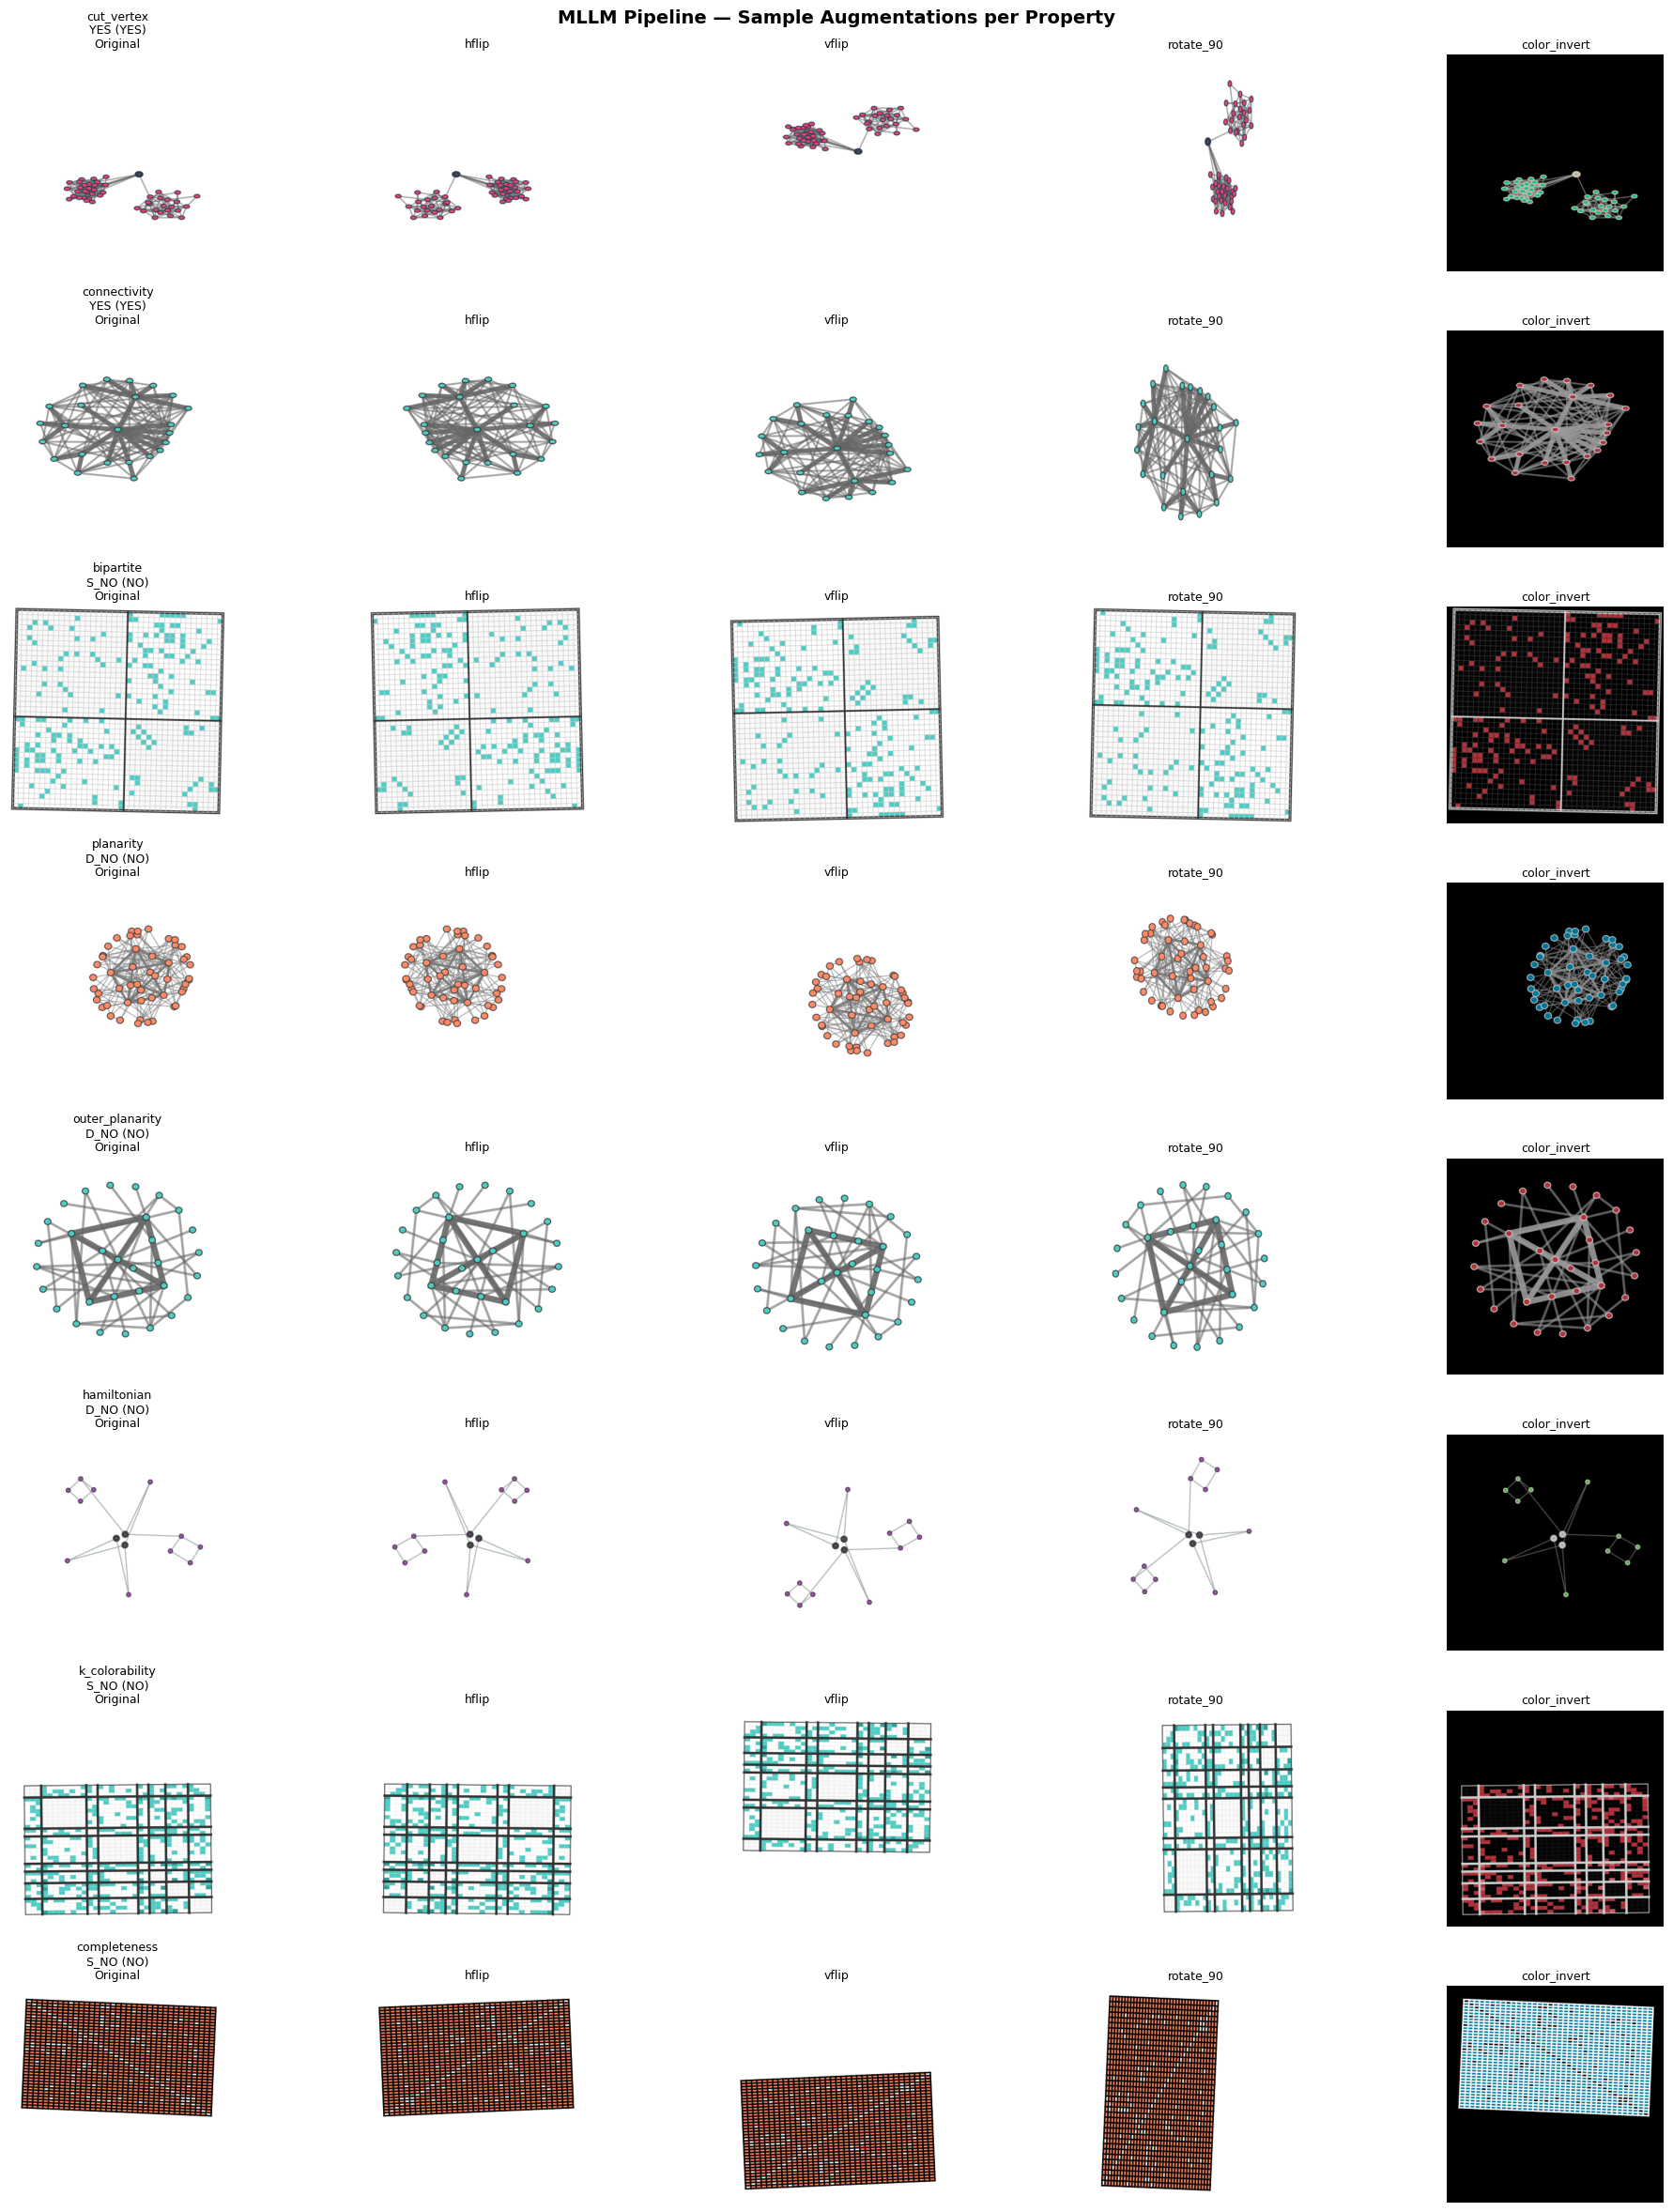

✓ Augmentation grid saved to mllm_results/mllm_augmentation_grid.png

✓ All visualization checks complete


In [10]:
# ============================================================================
# STEP 9.1: Dataset Visualization Sanity Checks
# ============================================================================
# Matches vision_model_finetune.ipynb's show_samples_comprehensive() exactly.

import PIL.ImageOps

# ── 1) Augmentation Grid: Original + 4 augmentations per property ─────────
def show_mllm_augmentation_grid(samples, config, n_per_prop=1):
    """
    Show one sample per property with original + 4 key augmentations.
    Layout: n_properties rows × 5 columns (Original + hflip + vflip + rotate_90 + color_invert)
    Mirrors vision_model_finetune's show_samples_comprehensive().
    """
    props = config.ALL_PROPERTIES
    n_props = len(props)

    aug_ops = ['original', 'hflip', 'vflip', 'rotate_90', 'color_invert']

    def apply_aug(img_pil, aug_name):
        if aug_name == 'original':
            return img_pil
        elif aug_name == 'hflip':
            return TF.hflip(img_pil)
        elif aug_name == 'vflip':
            return TF.vflip(img_pil)
        elif aug_name == 'rotate_90':
            return TF.rotate(img_pil, 90)
        elif aug_name == 'color_invert':
            return PIL.ImageOps.invert(img_pil.convert('RGB'))
        return img_pil

    # Group samples by property
    prop_samples = defaultdict(list)
    for s in samples:
        prop_samples[s['property']].append(s)

    fig, axes = plt.subplots(n_props, 5, figsize=(20, 3 * n_props))
    if n_props == 1:
        axes = [axes]

    for row, prop_name in enumerate(props):
        prop_list = prop_samples.get(prop_name, [])
        if not prop_list:
            for col in range(5):
                axes[row][col].text(0.5, 0.5, 'No data', ha='center', va='center')
                axes[row][col].axis('off')
            continue

        sample = random.choice(prop_list)
        img_pil = Image.open(sample['image_path']).convert('RGB')
        img_pil_resized = img_pil.resize((config.IMG_SIZE, config.IMG_SIZE))

        label_str = 'YES' if sample['label'] == 1 else 'NO'
        type_str = sample['sample_type'].upper()

        for col, aug_name in enumerate(aug_ops):
            ax = axes[row][col]
            img_display = apply_aug(img_pil_resized, aug_name)
            ax.imshow(img_display)

            if col == 0:
                ax.set_title(f"{prop_name}\n{type_str} ({label_str})\nOriginal", fontsize=9)
            else:
                ax.set_title(aug_name, fontsize=9)
            ax.axis('off')

    plt.suptitle('MLLM Pipeline — Sample Augmentations per Property', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(config.RESULTS_DIR, 'mllm_augmentation_grid.png'), dpi=150, bbox_inches='tight')
    plt.show()
    print("✓ Augmentation grid saved to mllm_results/mllm_augmentation_grid.png")


# ── Run all visualizations ────────────────────────────────────────────────
print("=" * 60)
print("VISUALIZATION SANITY CHECKS")
print("=" * 60)

# Sample grids

# Augmentation grid (one per property)
show_mllm_augmentation_grid(all_samples, config)

# Augmentation preview (original vs augmented)

# Reasoning text diagnostic

print("\n✓ All visualization checks complete")


In [ ]:
# ============================================================================
# STEP 10: Helper  Training Loop  (with per-epoch checkpoint + resume)
# ============================================================================

def run_training(mdl, proc, train_loader, val_loader, checkpoint_dir, config):
    """
    Full QLoRA training loop.

    Checkpointing strategy
    After every epoch:
      ó LoRA adapter weights  → <checkpoint_dir>/epoch_<N>_lora/
      ó Best LoRA (lowest val) → <checkpoint_dir>/best_lora/
      ó Resume state           → <checkpoint_dir>/resume_state.pt
        (contains: epoch, history, best_val_loss, best_epoch,
                   optimizer_state_dict, scheduler_state_dict)

    If a resume_state.pt already exists when this function is called, training
    automatically continues from the last completed epoch.  The corresponding
    LoRA weights are reloaded so the model is in the correct state.
    """
    from transformers import get_cosine_schedule_with_warmup
    from peft import set_peft_model_state_dict
    import safetensors.torch as sf_torch

    os.makedirs(checkpoint_dir, exist_ok=True)

    optimizer   = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, mdl.parameters()),
        lr=config.LEARNING_RATE, weight_decay=config.WEIGHT_DECAY
    )
    total_steps  = len(train_loader) * config.NUM_EPOCHS // config.GRAD_ACCUM_STEPS
    warmup_steps = int(total_steps * config.WARMUP_RATIO)
    scheduler    = get_cosine_schedule_with_warmup(
        optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps
    )

    history       = {'train_loss': [], 'val_loss': [], 'epoch': []}
    best_val_loss = float('inf')
    best_epoch    = 0
    start_epoch   = 0

    resume_path = os.path.join(checkpoint_dir, 'resume_state.pt')
    if os.path.exists(resume_path):
        print(f"        Resume checkpoint found: {resume_path}")
        state = torch.load(resume_path, map_location='cpu', weights_only=False)
        start_epoch   = state['epoch']        # last fully completed epoch
        history       = state['history']
        best_val_loss = state['best_val_loss']
        best_epoch    = state['best_epoch']

        # Reload LoRA weights from the last completed epoch
        epoch_lora = os.path.join(checkpoint_dir, f'epoch_{start_epoch}_lora')
        if os.path.exists(epoch_lora):
            sf_path = os.path.join(epoch_lora, 'adapter_model.safetensors')
            if os.path.exists(sf_path):
                adapter_weights = sf_torch.load_file(sf_path, device='cpu')
                set_peft_model_state_dict(mdl, adapter_weights)
                print(f"  ✓ LoRA weights restored from epoch {start_epoch}")
            else:
                print(f"  ΓÜá∩╕Å  safetensors file not found in {epoch_lora}, starting fresh")

        # Restore optimizer & scheduler
        optimizer.load_state_dict(state['optimizer_state_dict'])
        scheduler.load_state_dict(state['scheduler_state_dict'])
        print(f"  Γû╢  Resuming from epoch {start_epoch + 1} / {config.NUM_EPOCHS}")
    else:
        print(f"  Steps: {total_steps}  |  Warmup: {warmup_steps}  |  Epochs: {config.NUM_EPOCHS}")

    if start_epoch >= config.NUM_EPOCHS:
        print(f"  ✓ All {config.NUM_EPOCHS} epochs already completed  skipping training.")
        return history, best_epoch, best_val_loss

    for epoch in range(start_epoch, config.NUM_EPOCHS):
        mdl.train()
        total_train_loss = 0
        optimizer.zero_grad()

        pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{config.NUM_EPOCHS} [Train]')
        for step, batch in enumerate(pbar):
            batch = {k: v.to(mdl.device) if isinstance(v, torch.Tensor) else v
                     for k, v in batch.items()}
            outputs = mdl(**batch)
            loss    = outputs.loss / config.GRAD_ACCUM_STEPS
            loss.backward()
            total_train_loss += outputs.loss.item()

            if (step + 1) % config.GRAD_ACCUM_STEPS == 0:
                torch.nn.utils.clip_grad_norm_(mdl.parameters(), 1.0)
                optimizer.step(); scheduler.step(); optimizer.zero_grad()

            pbar.set_postfix({'loss': f'{outputs.loss.item():.4f}',
                              'lr':   f'{scheduler.get_last_lr()[0]:.2e}'})

        # flush remaining gradients
        if (step + 1) % config.GRAD_ACCUM_STEPS != 0:
            torch.nn.utils.clip_grad_norm_(mdl.parameters(), 1.0)
            optimizer.step(); scheduler.step(); optimizer.zero_grad()

        avg_train = total_train_loss / len(train_loader)

        # ΓöÇΓöÇ Validate ΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇ
        mdl.eval()
        total_val_loss = 0
        with torch.no_grad():
            for batch in tqdm(val_loader, desc=f'Epoch {epoch+1} [Val]', leave=False):
                batch = {k: v.to(mdl.device) if isinstance(v, torch.Tensor) else v
                         for k, v in batch.items()}
                total_val_loss += mdl(**batch).loss.item()
        avg_val = total_val_loss / len(val_loader)

        history['train_loss'].append(avg_train)
        history['val_loss'].append(avg_val)
        history['epoch'].append(epoch + 1)
        print(f"\n  Epoch {epoch+1}: Train={avg_train:.4f}  Val={avg_val:.4f}")

        # ΓöÇΓöÇ Save best checkpoint ΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇ
        if avg_val < best_val_loss:
            best_val_loss = avg_val
            best_epoch    = epoch + 1
            mdl.save_pretrained(os.path.join(checkpoint_dir, 'best_lora'))
            print(f"  → New best → {checkpoint_dir}/best_lora  (val={avg_val:.4f})")

        # ΓöÇΓöÇ Save per-epoch checkpoint (always) ΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇ
        epoch_lora_path = os.path.join(checkpoint_dir, f'epoch_{epoch+1}_lora')
        mdl.save_pretrained(epoch_lora_path)

        # ΓöÇΓöÇ Save resume state (always) ΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇΓöÇ
        torch.save({
            'epoch':                 epoch + 1,   # last completed epoch
            'history':               history,
            'best_val_loss':         best_val_loss,
            'best_epoch':            best_epoch,
            'optimizer_state_dict':  optimizer.state_dict(),
            'scheduler_state_dict':  scheduler.state_dict(),
        }, resume_path)
        print(f"  💾  Checkpoint saved: epoch_{epoch+1}_lora  |  resume_state.pt")

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print(f"\n{'='*55}")
    print(f"Training done!  Best epoch: {best_epoch},  Val loss: {best_val_loss:.4f}")
    print(f"Best weights: {checkpoint_dir}/best_lora")
    return history, best_epoch, best_val_loss


print("✓ run_training() defined  (per-epoch checkpoint + resume enabled)")


✓ run_training() defined  (per-epoch checkpoint + resume enabled)


---
## Pipeline 1 — Same Layout (yes + s_no)
Train and evaluate on same-layout negatives.  
The model learns to distinguish a **positive** graph from a **same-layout negative** (visually similar but structurally different).

## Pipeline 2 — Different Layout (yes + d_no)
Train and evaluate on different-layout negatives.  
The model learns to distinguish a **positive** graph from a **different-layout negative** (structurally proves the negative via a distinct visual certificate).

> Both pipelines use identical hyperparameters and save separate LoRA weights.


In [12]:
# ============================================================================
# PIPELINE 1: Train on Same Layout (yes + s_no)
# ============================================================================

print("=" * 65)
print("PIPELINE 1 — Same Layout: Training on yes + s_no")
print("=" * 65)
print(f"  Train: {len(sno_train)}  |  Val: {len(sno_val)}  |  Test: {len(sno_test)}")

# Load fresh base model and set global `processor`
# (train_collate_fn references `processor` from global scope)
model_p1, processor = load_base_model(config)
model_p1 = apply_lora_adapters(model_p1, config)

# Build dataloaders from s_no-only split (using s_no prompts for all samples)
train_loader_p1, val_loader_p1 = make_dataloaders(sno_train, sno_val, config, prompt_type='s_no')
print(f"  Train batches: {len(train_loader_p1)}  |  Val batches: {len(val_loader_p1)}")
print(f"  Using prompt_type='s_no' for consistent train/eval prompts")

# Train
history_p1, best_epoch_p1, best_val_loss_p1 = run_training(
    model_p1, processor,
    train_loader_p1, val_loader_p1,
    config.CHECKPOINT_DIR_SNO, config
)

# Free GPU memory before Pipeline 2
del model_p1
torch.cuda.empty_cache()
print("\n✓ Pipeline 1 complete — GPU memory freed for Pipeline 2.")


PIPELINE 1 — Same Layout: Training on yes + s_no
  Train: 11200  |  Val: 2400  |  Test: 2400
Loading base model: Qwen/Qwen2.5-VL-3B-Instruct ...
  bitsandbytes 0.49.2 available — using 4-bit NF4


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 824/824 [00:04<00:00, 192.70it/s]


  ✓ Model loaded in 4-bit QLoRA


  GPU memory after load: 2.41 GB
  LoRA applied  trainable: 37,152,768 / 2,071,177,216 (1.79%)
  Train batches: 11200  |  Val batches: 2400
  Using prompt_type='s_no' for consistent train/eval prompts
        Resume checkpoint found: ./mllm_checkpoints/pipeline_sno\resume_state.pt
  ✓ LoRA weights restored from epoch 3
  Γû╢  Resuming from epoch 4 / 3
  ✓ All 3 epochs already completed  skipping training.

✓ Pipeline 1 complete — GPU memory freed for Pipeline 2.


In [13]:
# ============================================================================
# PIPELINE 2: Train on Different Layout (yes + d_no)
# ============================================================================

print("=" * 65)
print("PIPELINE 2 — Different Layout: Training on yes + d_no")
print("=" * 65)
print(f"  Train: {len(dno_train)}  |  Val: {len(dno_val)}  |  Test: {len(dno_test)}")

# Load a fresh base model (independent from Pipeline 1)
model_p2, processor = load_base_model(config)
model_p2 = apply_lora_adapters(model_p2, config)

# Build dataloaders from d_no-only split (using d_no prompts for ALL samples including yes)
train_loader_p2, val_loader_p2 = make_dataloaders(dno_train, dno_val, config, prompt_type='d_no')
print(f"  Train batches: {len(train_loader_p2)}  |  Val batches: {len(val_loader_p2)}")
print(f"  Using prompt_type='d_no' for consistent train/eval prompts")

# Train
history_p2, best_epoch_p2, best_val_loss_p2 = run_training(
    model_p2, processor,
    train_loader_p2, val_loader_p2,
    config.CHECKPOINT_DIR_DNO, config
)

# Free GPU memory after training
del model_p2
torch.cuda.empty_cache()
print("\n✓ Pipeline 2 complete.")


PIPELINE 2 — Different Layout: Training on yes + d_no
  Train: 11200  |  Val: 2400  |  Test: 2400
Loading base model: Qwen/Qwen2.5-VL-3B-Instruct ...
  bitsandbytes 0.49.2 available — using 4-bit NF4


Loading weights: 100%|██████████| 824/824 [00:02<00:00, 410.74it/s]


  ✓ Model loaded in 4-bit QLoRA
  GPU memory after load: 4.20 GB
  LoRA applied  trainable: 37,152,768 / 2,071,177,216 (1.79%)
  Train batches: 11200  |  Val batches: 2400
  Using prompt_type='d_no' for consistent train/eval prompts
  Steps: 4200  |  Warmup: 210  |  Epochs: 3


Epoch 1/3 [Train]: 100%|██████████| 11200/11200 [2:18:19<00:00,  1.35it/s, loss=0.1624, lr=1.59e-04] 



  Epoch 1: Train=0.2073  Val=0.0977
  → New best → ./mllm_checkpoints/pipeline_dno/best_lora  (val=0.0977)
  💾  Checkpoint saved: epoch_1_lora  |  resume_state.pt


Epoch 2/3 [Train]: 100%|██████████| 11200/11200 [2:14:52<00:00,  1.38it/s, loss=0.0275, lr=5.48e-05] 



  Epoch 2: Train=0.0907  Val=0.0846
  → New best → ./mllm_checkpoints/pipeline_dno/best_lora  (val=0.0846)
  💾  Checkpoint saved: epoch_2_lora  |  resume_state.pt


Epoch 3/3 [Train]: 100%|██████████| 11200/11200 [2:13:23<00:00,  1.40it/s, loss=0.0352, lr=0.00e+00] 



  Epoch 3: Train=0.0780  Val=0.0777
  → New best → ./mllm_checkpoints/pipeline_dno/best_lora  (val=0.0777)
  💾  Checkpoint saved: epoch_3_lora  |  resume_state.pt

Training done!  Best epoch: 3,  Val loss: 0.0777
Best weights: ./mllm_checkpoints/pipeline_dno/best_lora

✓ Pipeline 2 complete.



Pipeline 1: 3 epochs, best=3
Pipeline 2: 3 epochs, best=3


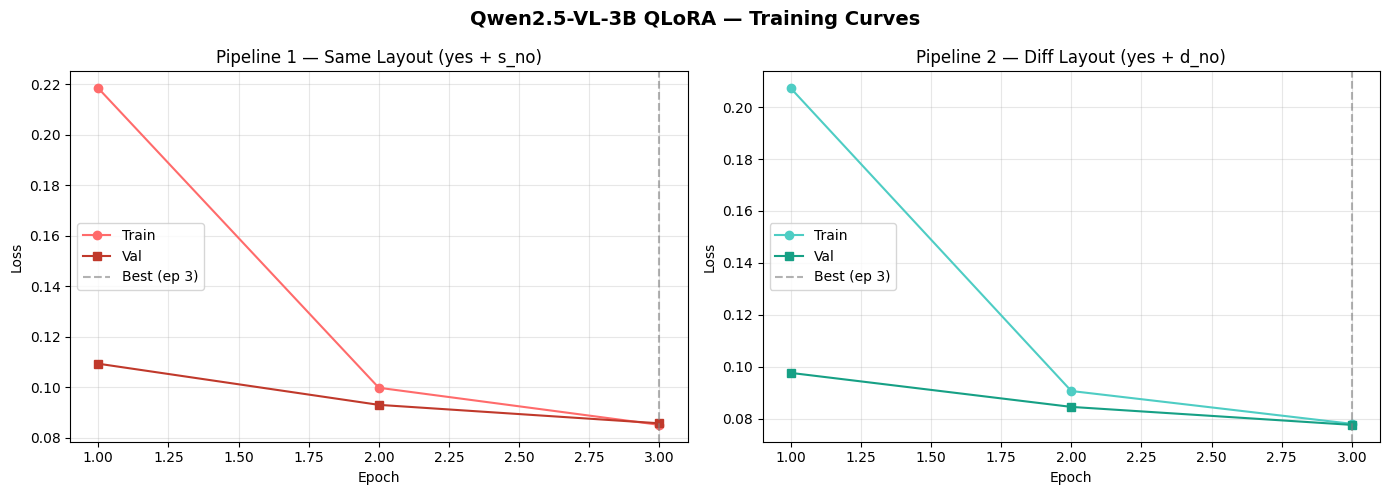

✓ Training curves saved


In [14]:
# ============================================================================
# STEP 11: Recover History & Plot Training Curves
# ============================================================================
# If the kernel was restarted mid-run, this loads history from saved checkpoints.

def load_history_from_checkpoint(checkpoint_dir):
    """Load history, best_epoch, best_val_loss from resume_state.pt."""
    resume_path = os.path.join(checkpoint_dir, 'resume_state.pt')
    if os.path.exists(resume_path):
        state = torch.load(resume_path, map_location='cpu', weights_only=False)
        print(f"  ✓ Loaded history from: {resume_path}")
        return state['history'], state['best_epoch'], state['best_val_loss']
    else:
        print(f"  ⚠️ No checkpoint at: {resume_path}")
        return {'train_loss': [], 'val_loss': [], 'epoch': []}, 0, float('inf')

# Try to recover P1 if not already in memory
if 'history_p1' not in dir() or not history_p1.get('epoch'):
    print("Recovering Pipeline 1 history from checkpoint...")
    history_p1, best_epoch_p1, best_val_loss_p1 = load_history_from_checkpoint(config.CHECKPOINT_DIR_SNO)

# Try to recover P2 if not already in memory
if 'history_p2' not in dir() or not history_p2.get('epoch'):
    print("Recovering Pipeline 2 history from checkpoint...") 
    history_p2, best_epoch_p2, best_val_loss_p2 = load_history_from_checkpoint(config.CHECKPOINT_DIR_DNO)

print(f"\nPipeline 1: {len(history_p1.get('epoch', []))} epochs, best={best_epoch_p1}")
print(f"Pipeline 2: {len(history_p2.get('epoch', []))} epochs, best={best_epoch_p2}")

# ── Plot training curves ─────────────────────────────────────────────
os.makedirs(config.RESULTS_DIR, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, history, best_epoch, title, color_train, color_val in [
    (axes[0], history_p1, best_epoch_p1,
     'Pipeline 1 — Same Layout (yes + s_no)', '#FF6B6B', '#c0392b'),
    (axes[1], history_p2, best_epoch_p2,
     'Pipeline 2 — Diff Layout (yes + d_no)', '#4ECDC4', '#16a085'),
]:
    if history.get('epoch'):
        ax.plot(history['epoch'], history['train_loss'], 'o-', label='Train', color=color_train)
        ax.plot(history['epoch'], history['val_loss'],   's-', label='Val',   color=color_val)
        ax.axvline(x=best_epoch, color='gray', linestyle='--', alpha=0.6, label=f'Best (ep {best_epoch})')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Qwen2.5-VL-3B QLoRA — Training Curves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(config.RESULTS_DIR, 'training_curves_both.png'), dpi=150)
plt.show()
print("✓ Training curves saved")


In [15]:
# ============================================================================
# STEP 12: Helper — Load Saved LoRA Model for Evaluation
# ============================================================================

def load_pipeline_model(checkpoint_dir, config):
    """
    Load base model + saved LoRA adapter weights for evaluation.
    Returns (model, processor) in eval mode.
    """
    best_lora_path = os.path.join(checkpoint_dir, 'best_lora')
    if not os.path.exists(best_lora_path):
        raise FileNotFoundError(f"No saved LoRA weights at: {best_lora_path}")

    print(f"Loading base model for evaluation...")
    mdl, proc = load_base_model(config)

    # Apply LoRA structure (needed before loading weights)
    mdl = apply_lora_adapters(mdl, config)

    # Load saved adapter weights
    mdl.load_adapter(best_lora_path, adapter_name='default')
    mdl.eval()
    print(f"  ✓ LoRA weights loaded from: {best_lora_path}")
    return mdl, proc


print("✓ load_pipeline_model() defined")


✓ load_pipeline_model() defined


In [ ]:
# ============================================================================
# STEP 12.5: TTA REMOVED - Property-aware augmentation now used at training
# ============================================================================
# TTA (Test Time Augmentation) has been removed from inference.
# The per-property, per-layout transforms are now applied during training
# via TrainAugmentation, which uses the same AUG_GEOMETRIC_TRANSFORMS config.
print('✓ TTA removed — property-aware augmentation applied during training instead')


✓ TTA removed — property-aware augmentation applied during training instead


In [17]:
# ============================================================================
# STEP 13: Helper — Single-Sample Inference (with optional TTA voting)
# ============================================================================

@torch.no_grad()
def _predict_single_image(sample: dict, image: Image.Image, mdl, proc, prompt_type: str = None) -> Tuple[str, str, str, float]:
    """
    Internal helper: run one prediction for a provided image.
    Returns: (prediction, response_text, prompt_used, confidence)
    """
    no_type = prompt_type if prompt_type else sample['sample_type']
    if no_type == 'yes':
        no_type = 's_no' if (prompt_type is None or prompt_type == 's_no') else 'd_no'

    prompt = build_prompt(sample['property'], no_type)

    messages = [{
        'role': 'user',
        'content': [
            {'type': 'image', 'image': image},
            {'type': 'text', 'text': prompt},
        ],
    }]

    text = proc.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = proc(text=[text], images=[image], return_tensors='pt', padding=True).to(mdl.device)

    out_ids = mdl.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False,
        pad_token_id=proc.tokenizer.pad_token_id,
    )

    generated = out_ids[0][inputs['input_ids'].shape[1]:]
    response = proc.decode(generated, skip_special_tokens=True).strip()

    # Parse YES/NO + heuristic confidence
    u = response.upper()
    if u.startswith('YES') or 'YES:' in u[:15]:
        prediction, confidence = 'YES', 0.85
    elif u.startswith('NO') or 'NO:' in u[:15]:
        prediction, confidence = 'NO', 0.85
    elif 'YES' in u[:80]:
        prediction, confidence = 'YES', 0.65
    elif 'NO' in u[:80]:
        prediction, confidence = 'NO', 0.65
    else:
        prediction, confidence = 'NO', 0.50

    return prediction, response, prompt, confidence


@torch.no_grad()
def predict_sample(sample: dict, mdl, proc, prompt_type: str = None, use_tta: bool = False) -> Tuple[str, str, str, float, dict]:
    """
    Run inference on one sample, optionally with TTA majority vote.

    Returns:
      prediction, response_text, prompt_used, confidence, extra
    """
    image = Image.open(sample['image_path']).convert('RGB')

    # No TTA path
    pred, resp, prompt, conf = _predict_single_image(sample, image, mdl, proc, prompt_type=prompt_type)
    extra = {'mode': 'base', 'tta_votes': {'YES': int(pred == 'YES'), 'NO': int(pred == 'NO')}, 'tta_count': 1}
    return pred, resp, prompt, conf, extra



print("✓ predict_sample() defined (base + optional TTA voting)")

✓ predict_sample() defined (base + optional TTA voting)


In [18]:
# ============================================================================
# STEP 14: Evaluate Both Pipelines on Their Own Test Sets
# ============================================================================

def evaluate_pipeline(pipeline_label, test_samples, checkpoint_dir, prompt_type, config, use_tta=None):
    """
    Load the saved model for a pipeline and evaluate on its own test set.
    prompt_type: 's_no' for Pipeline 1, 'd_no' for Pipeline 2.
    use_tta: None -> config.USE_TTA

    Returns list of result dicts.
    """
    if use_tta is None:
        use_tta = config.USE_TTA

    print(f"\n{'='*65}")
    print(f"Evaluating {pipeline_label} (prompt_type={prompt_type}, use_tta={use_tta})")
    print(f"  Test samples: {len(test_samples)}")
    print(f"{'='*65}")

    # Load the pipeline-specific model
    mdl, proc = load_pipeline_model(checkpoint_dir, config)

    # Set global processor so predict_sample can use it if needed
    global processor
    processor = proc

    results = []
    for sample in tqdm(test_samples, desc=pipeline_label):
        try:
            pred, resp, prompt, conf, extra = predict_sample(
                sample,
                mdl,
                proc,
                prompt_type=prompt_type,
                use_tta=use_tta,
            )

            results.append({
                'image_path': sample['image_path'],
                'property': sample['property'],
                'true_label': sample['label'],
                'pred_label': 1 if pred == 'YES' else 0,
                'prediction': pred,
                'sample_type': sample['sample_type'],
                'response': resp[:500],
                'prompt': prompt,
                'confidence': conf,
                'eval_mode': extra.get('mode', 'base'),
                'tta_votes_yes': extra.get('tta_votes', {}).get('YES', 0),
                'tta_votes_no': extra.get('tta_votes', {}).get('NO', 0),
                'tta_count': extra.get('tta_count', 1),
            })

        except Exception as e:
            results.append({
                'image_path': sample['image_path'],
                'property': sample['property'],
                'true_label': sample['label'],
                'pred_label': -1,
                'prediction': 'ERROR',
                'sample_type': sample['sample_type'],
                'response': str(e),
                'prompt': '',
                'confidence': 0.0,
                'eval_mode': 'error',
                'tta_votes_yes': 0,
                'tta_votes_no': 0,
                'tta_count': 0,
            })

        if len(results) % 30 == 0 and torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Free GPU
    del mdl
    torch.cuda.empty_cache()
    print(f"  ✓ Done. Pipeline model freed from GPU.")
    return results


# ── Pipeline 1: evaluated on sno_test (yes + s_no) ──────────────────
results_p1 = evaluate_pipeline(
    'Pipeline 1 — Same Layout (s_no)',
    sno_test,
    config.CHECKPOINT_DIR_SNO,
    prompt_type='s_no',
    config=config,
    use_tta=False,
)

# ── Pipeline 2: evaluated on dno_test (yes + d_no) ──────────────────
results_p2 = evaluate_pipeline(
    'Pipeline 2 — Diff Layout (d_no)',
    dno_test,
    config.CHECKPOINT_DIR_DNO,
    prompt_type='d_no',
    config=config,
    use_tta=False,
)

# Optional baseline-vs-TTA comparison (computationally expensive)

print(f"\n✓ Both pipelines evaluated")
print(f"  P1 results: {len(results_p1)} samples")
print(f"  P2 results: {len(results_p2)} samples")


Evaluating Pipeline 1 — Same Layout (s_no) (prompt_type=s_no, use_tta=False)
  Test samples: 2400
Loading base model for evaluation...
Loading base model: Qwen/Qwen2.5-VL-3B-Instruct ...
  bitsandbytes 0.49.2 available — using 4-bit NF4


Loading weights: 100%|██████████| 824/824 [00:02<00:00, 404.87it/s]


  ✓ Model loaded in 4-bit QLoRA
  GPU memory after load: 4.52 GB
  LoRA applied  trainable: 37,152,768 / 2,071,177,216 (1.79%)
  ✓ LoRA weights loaded from: ./mllm_checkpoints/pipeline_sno\best_lora


Pipeline 1 — Same Layout (s_no): 100%|██████████| 2400/2400 [2:06:19<00:00,  3.16s/it]  


  ✓ Done. Pipeline model freed from GPU.

Evaluating Pipeline 2 — Diff Layout (d_no) (prompt_type=d_no, use_tta=False)
  Test samples: 2400
Loading base model for evaluation...
Loading base model: Qwen/Qwen2.5-VL-3B-Instruct ...
  bitsandbytes 0.49.2 available — using 4-bit NF4


Loading weights: 100%|██████████| 824/824 [00:01<00:00, 420.88it/s]


  ✓ Model loaded in 4-bit QLoRA
  GPU memory after load: 4.23 GB
  LoRA applied  trainable: 37,152,768 / 2,071,177,216 (1.79%)
  ✓ LoRA weights loaded from: ./mllm_checkpoints/pipeline_dno\best_lora


Pipeline 2 — Diff Layout (d_no): 100%|██████████| 2400/2400 [2:07:08<00:00,  3.18s/it]  

  ✓ Done. Pipeline model freed from GPU.

✓ Both pipelines evaluated
  P1 results: 2400 samples
  P2 results: 2400 samples


In [19]:
# ============================================================================
# STEP 15: Calculate Metrics (COMPARISON: Exp1 vs Exp2)
# ============================================================================

df_exp1 = pd.DataFrame(results_p1)
df_exp2 = pd.DataFrame(results_p2)

def compute_metrics(df):
    """Compute metrics for one experiment dataframe."""
    df_valid = df[df['pred_label'] != -1].copy()
    y_true = df_valid['true_label'].values
    y_pred = df_valid['pred_label'].values

    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'n_samples': len(df_valid),
    }

    per_prop = {}
    for prop in config.ALL_PROPERTIES:
        prop_df = df_valid[df_valid['property'] == prop]
        if len(prop_df) > 0:
            per_prop[prop] = {
                'accuracy': accuracy_score(prop_df['true_label'], prop_df['pred_label']),
                'f1': f1_score(prop_df['true_label'], prop_df['pred_label'], zero_division=0),
                'n': len(prop_df),
            }

    return metrics, per_prop, df_valid

metrics_exp1, per_prop_exp1, df_exp1_valid = compute_metrics(df_exp1)
metrics_exp2, per_prop_exp2, df_exp2_valid = compute_metrics(df_exp2)

# Compatibility aliases for downstream cells
metrics_p1, metrics_p2 = metrics_exp1, metrics_exp2
per_prop_p1, per_prop_p2 = per_prop_exp1, per_prop_exp2
df_p1, df_p2 = df_exp1_valid, df_exp2_valid

print('=' * 60)
print('COMPARISON: Experiment 1 (s_no) vs Experiment 2 (d_no)')
print('=' * 60)

print(f"\n{'Metric':<12} {'Exp1 (s_no)':<15} {'Exp2 (d_no)':<15} {'Delta (Exp2-Exp1)':<18}")
print('-' * 64)
for m in ['accuracy', 'precision', 'recall', 'f1']:
    delta = metrics_exp2[m] - metrics_exp1[m]
    print(f"{m:<12} {metrics_exp1[m]:<15.4f} {metrics_exp2[m]:<15.4f} {delta:+.4f}")

visual_proof_gain = metrics_exp2['accuracy'] - metrics_exp1['accuracy']
print(f"\nVisual Proof Gain: {visual_proof_gain:+.4f}")
if visual_proof_gain > 0.05:
    print('d_no significantly easier to detect')
elif visual_proof_gain > 0:
    print('slight improvement with d_no')
else:
    print('no improvement with d_no')

print(f"\n{'Property':<18} {'Exp1 (s_no)':<12} {'Exp2 (d_no)':<12} {'Delta':<10}")
print('-' * 56)
for prop in config.ALL_PROPERTIES:
    exp1_acc = per_prop_exp1.get(prop, {}).get('accuracy', 0)
    exp2_acc = per_prop_exp2.get(prop, {}).get('accuracy', 0)
    delta = exp2_acc - exp1_acc
    indicator = 'OK' if delta > 0.1 else 'MID' if delta > 0 else 'LOW'
    print(f"{prop:<18} {exp1_acc:<12.4f} {exp2_acc:<12.4f} {delta:+.4f} {indicator}")

COMPARISON: Experiment 1 (s_no) vs Experiment 2 (d_no)

Metric       Exp1 (s_no)     Exp2 (d_no)     Delta (Exp2-Exp1) 
----------------------------------------------------------------
accuracy     0.9917          0.9996          +0.0079
precision    0.9844          1.0000          +0.0156
recall       0.9992          0.9992          +0.0000
f1           0.9917          0.9996          +0.0079

Visual Proof Gain: +0.0079
slight improvement with d_no

Property           Exp1 (s_no)  Exp2 (d_no)  Delta     
--------------------------------------------------------
cut_vertex         0.9933       1.0000       +0.0067 MID
connectivity       0.9700       1.0000       +0.0300 MID
bipartite          1.0000       1.0000       +0.0000 LOW
planarity          0.9733       1.0000       +0.0267 MID
outer_planarity    1.0000       1.0000       +0.0000 LOW
hamiltonian        1.0000       1.0000       +0.0000 LOW
k_colorability     1.0000       1.0000       +0.0000 LOW
completeness       0.9967       0


CUT_VERTEX

--------------------------------------------------------------------------------
ROW: YES
--------------------------------------------------------------------------------

[Exp1] Exp1 (s_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Cut Vertex

Rules:
- YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.
- NO if: Same bridge-like layout, but dense clusters have edges between them (2-connected, no cut vertex).

Question: Does this graph have Cut Vertex? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


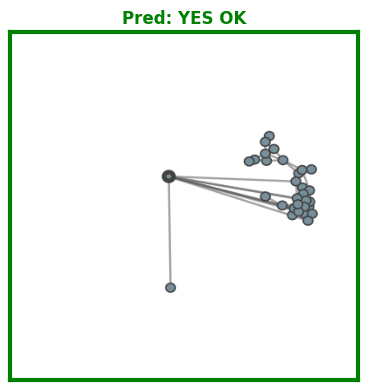


RESPONSE:
YES: The BOLD node is an articulation point. The visual shows it connecting separate dense regions. The graph would fragment into 2 parts if this node were removed.

[Exp2] Exp2 (d_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Cut Vertex

Rules:
- YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.
- NO if: Ear decomposition (flower pattern) with ears spreading around central path, proving 2-connectivity.

Question: Does this graph have Cut Vertex? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


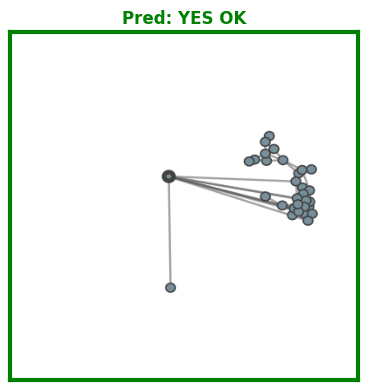


RESPONSE:
YES: The BOLD node is an articulation point. The visual shows it connecting separate dense regions. The graph would fragment into 2 parts if this node were removed.

--------------------------------------------------------------------------------
ROW: NO
--------------------------------------------------------------------------------

[Exp1] Exp1: s_no
Correct: 148  |  Wrong: 2  |  Total: 150

PROMPT:
Property: Cut Vertex

Rules:
- YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.
- NO if: Same bridge-like layout, but dense clusters have edges between them (2-connected, no cut vertex).

Question: Does this graph have Cut Vertex? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


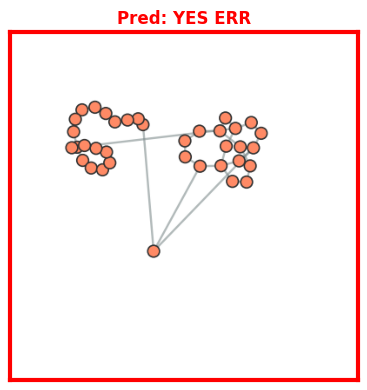


RESPONSE:
YES: The BOLD node is an articulation point. The visual shows it connecting separate dense regions. The graph would fragment into 2 parts if this node were removed.

[Exp2] Exp2: d_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Cut Vertex

Rules:
- YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.
- NO if: Ear decomposition (flower pattern) with ears spreading around central path, proving 2-connectivity.

Question: Does this graph have Cut Vertex? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


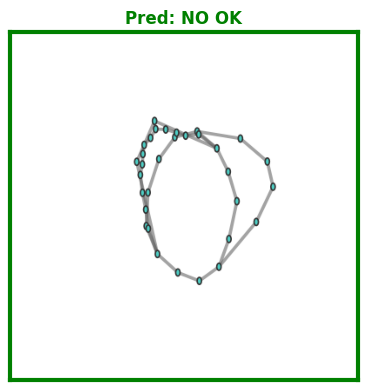


RESPONSE:
NO: The ear decomposition visualization proves 2-connectivity. The base cycle and 4 attached ears form a redundant structure with no cut vertices.

CONNECTIVITY

--------------------------------------------------------------------------------
ROW: YES
--------------------------------------------------------------------------------

[Exp1] Exp1 (s_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Graph Connectivity

Rules:
- YES if: BFS tree on concentric circles with BOLD spanning tree edges in a single component graph.
- NO if: BFS tree on concentric circles but BOLD spanning tree only covers maximum component (not all components).

Question: Does this graph have Graph Connectivity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


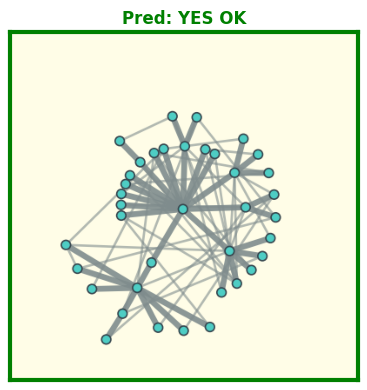


RESPONSE:
YES: The graph is fully connected. Starting from the center, the BFS tree reaches every node as shown by the BOLD edges forming a spanning structure.

[Exp2] Exp2 (d_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Graph Connectivity

Rules:
- YES if: BFS tree on concentric circles with BOLD spanning tree edges in a single component graph.
- NO if: Spatially SEPARATED clusters with clear visible gaps between them, showing disconnection.

Question: Does this graph have Graph Connectivity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


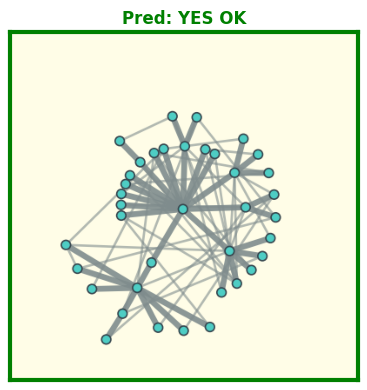


RESPONSE:
YES: The graph is fully connected. Starting from the center, the BFS tree reaches every node as shown by the BOLD edges forming a spanning structure.

--------------------------------------------------------------------------------
ROW: NO
--------------------------------------------------------------------------------

[Exp1] Exp1: s_no
Correct: 141  |  Wrong: 9  |  Total: 150

PROMPT:
Property: Graph Connectivity

Rules:
- YES if: BFS tree on concentric circles with BOLD spanning tree edges in a single component graph.
- NO if: BFS tree on concentric circles but BOLD spanning tree only covers maximum component (not all components).

Question: Does this graph have Graph Connectivity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


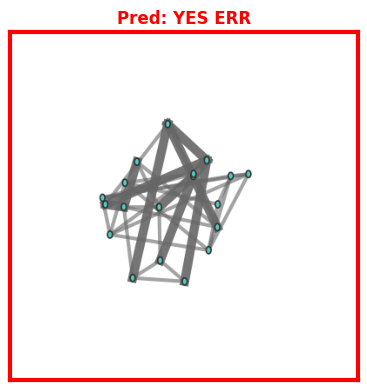


RESPONSE:
YES: The graph is fully connected. Starting from the center, the BFS tree reaches every node as shown by the BOLD edges forming a spanning structure.

[Exp2] Exp2: d_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Graph Connectivity

Rules:
- YES if: BFS tree on concentric circles with BOLD spanning tree edges in a single component graph.
- NO if: Spatially SEPARATED clusters with clear visible gaps between them, showing disconnection.

Question: Does this graph have Graph Connectivity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


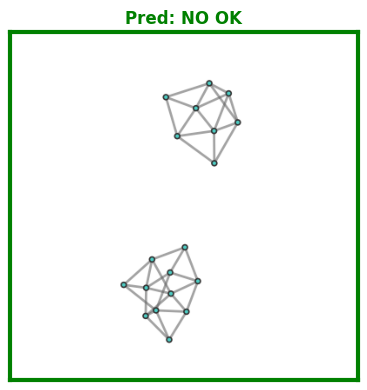


RESPONSE:
NO: The spatially separated layout reveals 2 isolated components with sizes 10, 9. Each cluster is internally connected but has no edges to other clusters.

BIPARTITE

--------------------------------------------------------------------------------
ROW: YES
--------------------------------------------------------------------------------

[Exp1] Exp1 (s_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.
- NO if: Matrix sorted into 2 blocks on diagonal, but diagonal blocks HAVE edges inside (colored cells in diagonal blocks, not all empty).

Question: Does this graph have Bipartite Graph? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


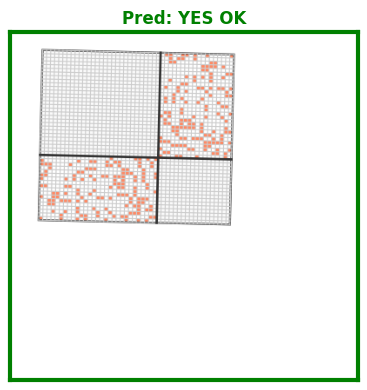


RESPONSE:
YES: The graph can be 2-colored. The 45-node graph partitions into sets of 28 and 17 nodes. Diagonal blocks are empty, proving no odd cycles exist.

[Exp2] Exp2 (d_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.
- NO if: Odd cycle HIGHLIGHTED in top-left block. Cycle nodes connected sequentially forming odd-length closed path.

Question: Does this graph have Bipartite Graph? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


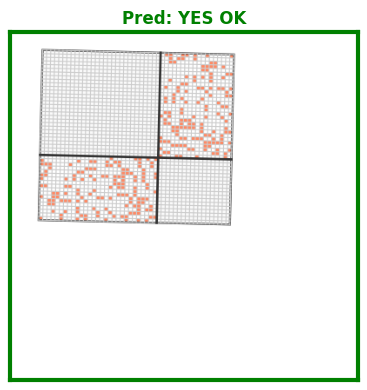


RESPONSE:
YES: The graph can be 2-colored. The 48-node graph partitions into sets of 30 and 18 nodes. Diagonal blocks are empty, proving no odd cycles exist.

--------------------------------------------------------------------------------
ROW: NO
--------------------------------------------------------------------------------

[Exp1] Exp1: s_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.
- NO if: Matrix sorted into 2 blocks on diagonal, but diagonal blocks HAVE edges inside (colored cells in diagonal blocks, not all empty).

Question: Does this graph have Bipartite Graph? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


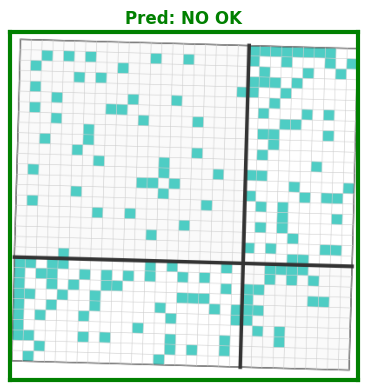


RESPONSE:
NO: The graph is NOT bipartite. Although sorted into 2 blocks, the diagonal blocks contain colored cells indicating edges within partitions. This violates the bipartite property.

[Exp2] Exp2: d_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.
- NO if: Odd cycle HIGHLIGHTED in top-left block. Cycle nodes connected sequentially forming odd-length closed path.

Question: Does this graph have Bipartite Graph? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


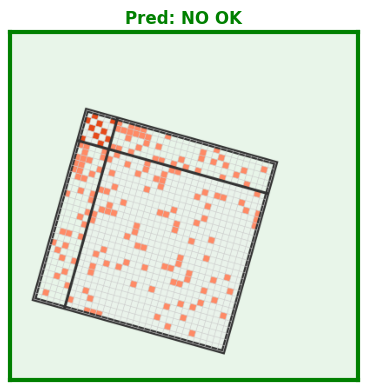


RESPONSE:
NO: An odd-length cycle (5 nodes) is highlighted. This cycle cannot be 2-colored since alternating colors return to the start with a conflict.

PLANARITY

--------------------------------------------------------------------------------
ROW: YES
--------------------------------------------------------------------------------

[Exp1] Exp1 (s_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Planarity

Rules:
- YES if: Planar embedding with ZERO edge crossings. Clean spread layout with no lines intersecting.
- NO if: Same spread layout style as YES, but some edges visibly CROSS each other (non-planar edges).

Question: Does this graph have Planarity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


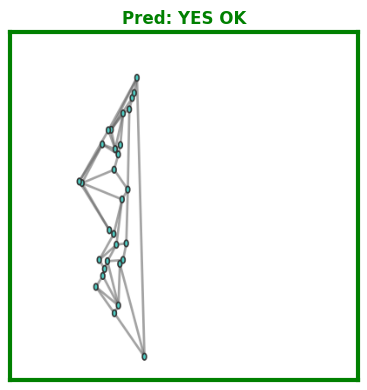


RESPONSE:
YES: The graph is planar. The embedding shows all 53 edges drawn without any crossings. The layout achieves a valid planar representation.

[Exp2] Exp2 (d_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Planarity

Rules:
- YES if: Planar embedding with ZERO edge crossings. Clean spread layout with no lines intersecting.
- NO if: BOLD edges highlight K₅ (pentagon with all diagonals) or K₃,₃ (bipartite 3+3) minor proving non-planarity.

Question: Does this graph have Planarity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


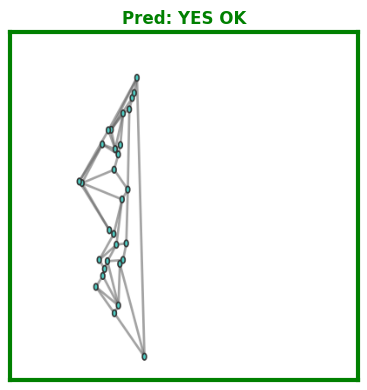


RESPONSE:
YES: Valid planar embedding achieved. The spring/planar layout positions all nodes such that edges do not cross. This proves the graph can be drawn on a plane.

--------------------------------------------------------------------------------
ROW: NO
--------------------------------------------------------------------------------

[Exp1] Exp1: s_no
Correct: 142  |  Wrong: 8  |  Total: 150

PROMPT:
Property: Planarity

Rules:
- YES if: Planar embedding with ZERO edge crossings. Clean spread layout with no lines intersecting.
- NO if: Same spread layout style as YES, but some edges visibly CROSS each other (non-planar edges).

Question: Does this graph have Planarity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


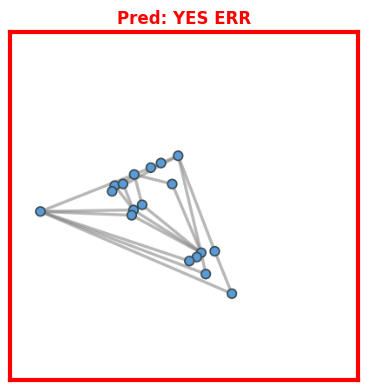


RESPONSE:
YES: The graph is planar. The embedding shows all 39 edges drawn without any crossings. The layout achieves a valid planar representation.

[Exp2] Exp2: d_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Planarity

Rules:
- YES if: Planar embedding with ZERO edge crossings. Clean spread layout with no lines intersecting.
- NO if: BOLD edges highlight K₅ (pentagon with all diagonals) or K₃,₃ (bipartite 3+3) minor proving non-planarity.

Question: Does this graph have Planarity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


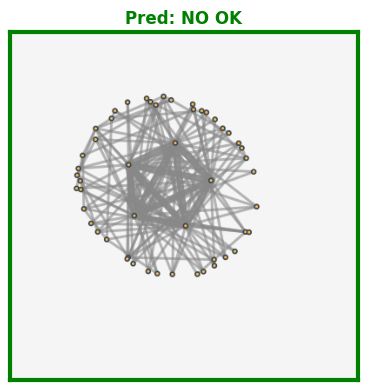


RESPONSE:
NO: Non-planar proven by K₅ minor. The highlighted structure shows the forbidden minor with all required edges present (BOLD).

OUTER_PLANARITY

--------------------------------------------------------------------------------
ROW: YES
--------------------------------------------------------------------------------

[Exp1] Exp1 (s_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Outer-Planarity

Rules:
- YES if: Outer-planar embedding with ALL vertices on outer face and ZERO edge crossings.
- NO if: Outer-planar style layout but some edges visibly CROSS each other.

Question: Does this graph have Outer-Planarity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


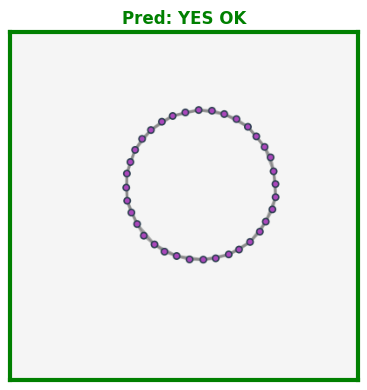


RESPONSE:
YES: The graph is outer-planar with 38 outer-face vertices. The edge arrangement inside the circle has no crossings, proving outer-planarity.

[Exp2] Exp2 (d_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Outer-Planarity

Rules:
- YES if: Outer-planar embedding with ALL vertices on outer face and ZERO edge crossings.
- NO if: BOLD edges highlight K₄ (4 nodes fully connected) or K₂,₃ (2+3 bipartite) minor proving non-outer-planarity.

Question: Does this graph have Outer-Planarity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


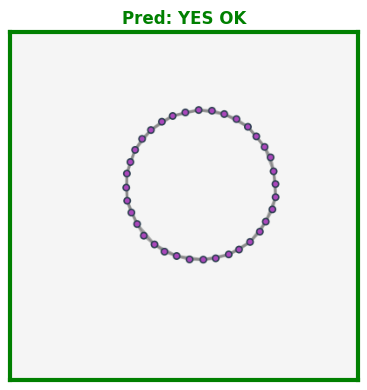


RESPONSE:
YES: The graph is outer-planar with 38 outer-face vertices. The edge arrangement inside the circle has no crossings, proving outer-planarity.

--------------------------------------------------------------------------------
ROW: NO
--------------------------------------------------------------------------------

[Exp1] Exp1: s_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Outer-Planarity

Rules:
- YES if: Outer-planar embedding with ALL vertices on outer face and ZERO edge crossings.
- NO if: Outer-planar style layout but some edges visibly CROSS each other.

Question: Does this graph have Outer-Planarity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


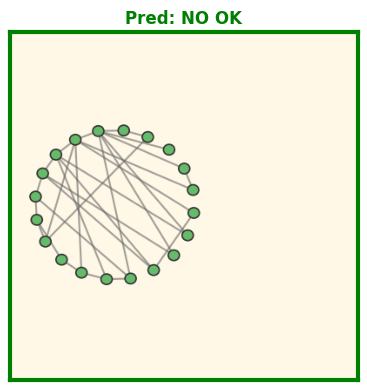


RESPONSE:
NO: Not outer-planar. The same circular layout reveals unavoidable edge crossings, indicating a K₄ or K₂,₃ minor exists.

[Exp2] Exp2: d_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Outer-Planarity

Rules:
- YES if: Outer-planar embedding with ALL vertices on outer face and ZERO edge crossings.
- NO if: BOLD edges highlight K₄ (4 nodes fully connected) or K₂,₃ (2+3 bipartite) minor proving non-outer-planarity.

Question: Does this graph have Outer-Planarity? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


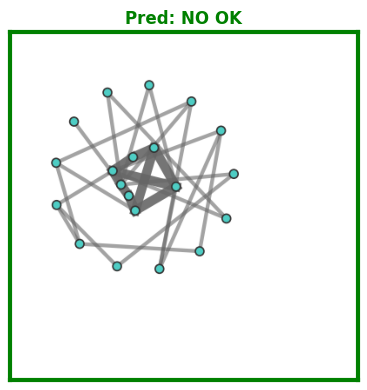


RESPONSE:
NO: The K₄ minor is highlighted with BOLD edges. By the forbidden minor characterization, this graph is not outer-planar.

HAMILTONIAN

--------------------------------------------------------------------------------
ROW: YES
--------------------------------------------------------------------------------

[Exp1] Exp1 (s_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Hamiltonian Cycle

Rules:
- YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.
- NO if: Longest cycle on outer circle (LOOKS like Hamiltonian) but some nodes are INSIDE the cycle.

Question: Does this graph have Hamiltonian Cycle? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


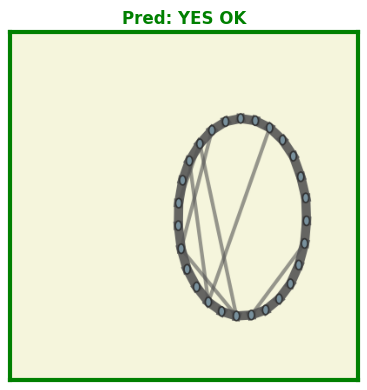


RESPONSE:
YES: The graph has a Hamiltonian cycle. The BOLD edges form a cycle visiting all 30 nodes exactly once, then returning to the start.

[Exp2] Exp2 (d_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Hamiltonian Cycle

Rules:
- YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.
- NO if: Cut-set (S) shown as BOLD highlighted nodes at center. k(G-S) > |S| proving no Hamiltonian cycle.

Question: Does this graph have Hamiltonian Cycle? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


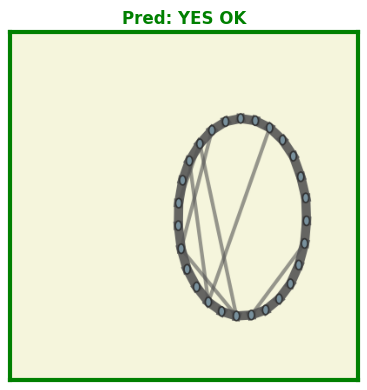


RESPONSE:
YES: The graph has a Hamiltonian cycle. The BOLD edges form a cycle visiting all 28 nodes exactly once, then returning to the start.

--------------------------------------------------------------------------------
ROW: NO
--------------------------------------------------------------------------------

[Exp1] Exp1: s_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Hamiltonian Cycle

Rules:
- YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.
- NO if: Longest cycle on outer circle (LOOKS like Hamiltonian) but some nodes are INSIDE the cycle.

Question: Does this graph have Hamiltonian Cycle? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


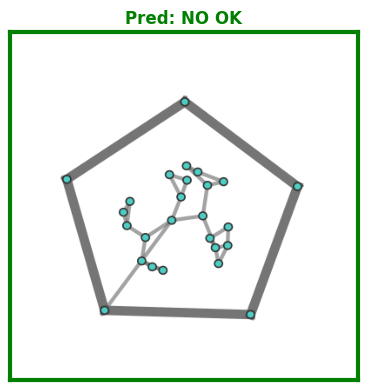


RESPONSE:
NO: No Hamiltonian cycle possible. The best cycle covers 5/24 nodes. Interior nodes indicate structural obstacles to a Hamilton path.

[Exp2] Exp2: d_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Hamiltonian Cycle

Rules:
- YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.
- NO if: Cut-set (S) shown as BOLD highlighted nodes at center. k(G-S) > |S| proving no Hamiltonian cycle.

Question: Does this graph have Hamiltonian Cycle? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


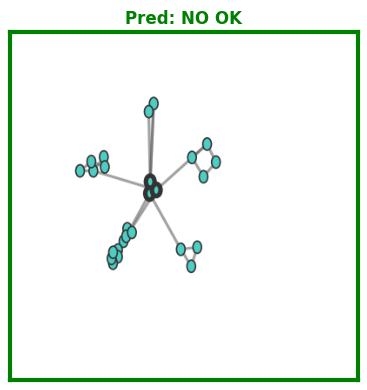


RESPONSE:
NO: Non-Hamiltonicity proven. The 3 cut-set nodes (BOLD) leave 5 isolated components when removed. This violates the necessary condition.

K_COLORABILITY

--------------------------------------------------------------------------------
ROW: YES
--------------------------------------------------------------------------------

[Exp1] Exp1 (s_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: 4-Colorability

Rules:
- YES if: Matrix with ≤4 EMPTY diagonal blocks. Each block = one color class (independent set). Every diagonal block is completely empty.
- NO if: Matrix with >4 EMPTY diagonal blocks (5-8 blocks visible on diagonal), needs more than 4 colors.

Question: Does this graph have 4-Colorability? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


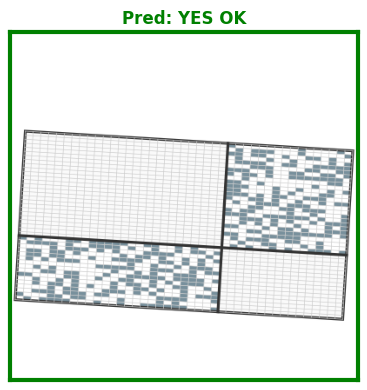


RESPONSE:
YES: The graph can be colored with 2 colors. Matrix analysis shows 2 blocks with sizes 27, 19. No two adjacent nodes share a color class.

[Exp2] Exp2 (d_no rules)
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: 4-Colorability

Rules:
- YES if: Matrix with ≤4 EMPTY diagonal blocks. Each block = one color class (independent set). Every diagonal block is completely empty.
- NO if: Matrix with highlighted K₅/K₆/K₇/K₈ clique (BOLD highlighted edges forming complete subgraph in top-left block). Except diagonal, every cell in top-left block is filled, showing large clique.

Question: Does this graph have 4-Colorability? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


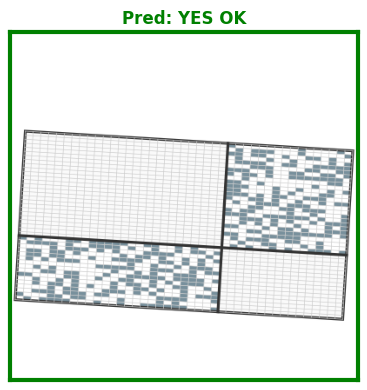


RESPONSE:
YES: The graph can be colored with 2 colors. Matrix analysis shows 2 blocks with sizes 28, 17. No two adjacent nodes share a color class.

--------------------------------------------------------------------------------
ROW: NO
--------------------------------------------------------------------------------

[Exp1] Exp1: s_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: 4-Colorability

Rules:
- YES if: Matrix with ≤4 EMPTY diagonal blocks. Each block = one color class (independent set). Every diagonal block is completely empty.
- NO if: Matrix with >4 EMPTY diagonal blocks (5-8 blocks visible on diagonal), needs more than 4 colors.

Question: Does this graph have 4-Colorability? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


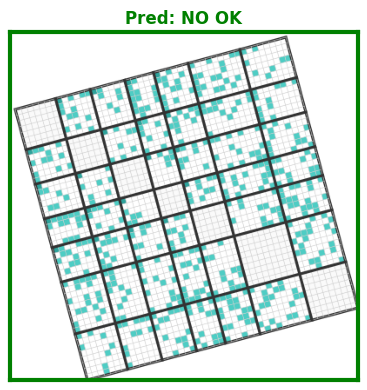


RESPONSE:
NO: The graph requires more than 4 colors. The matrix shows 5 empty diagonal blocks - 5 independent sets are needed, proving chromatic number > 4.

[Exp2] Exp2: d_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: 4-Colorability

Rules:
- YES if: Matrix with ≤4 EMPTY diagonal blocks. Each block = one color class (independent set). Every diagonal block is completely empty.
- NO if: Matrix with highlighted K₅/K₆/K₇/K₈ clique (BOLD highlighted edges forming complete subgraph in top-left block). Except diagonal, every cell in top-left block is filled, showing large clique.

Question: Does this graph have 4-Colorability? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


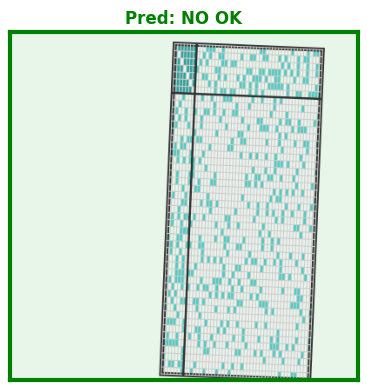


RESPONSE:
NO: Not 4-colorable due to 7-clique. The highlighted complete subgraph forces 7 colors minimum. The clique edges are shown in BOLD.

COMPLETENESS

--------------------------------------------------------------------------------
ROW: YES
--------------------------------------------------------------------------------

[Exp1] Exp1 (s_no rules)
Correct: 149  |  Wrong: 1  |  Total: 150

PROMPT:
Property: Graph Completeness

Rules:
- YES if: Full adjacency matrix - ALL cells filled, all edges present between every pair of nodes. Only diagonal cells are empty (no self-loops).
- NO if: There are some missing edges (empty cells outside diagonal) in the adjacency matrix, showing it is not complete.

Question: Does this graph have Graph Completeness? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


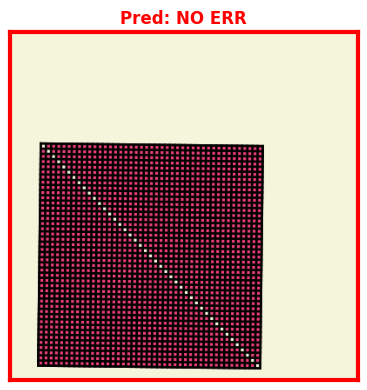


RESPONSE:
NO: Not complete. The graph has 894 of 903 possible edges (99.1% complete). The empty cells in the matrix show 9 missing edges.

[Exp2] Exp2 (d_no rules)
Correct: 149  |  Wrong: 1  |  Total: 150

PROMPT:
Property: Graph Completeness

Rules:
- YES if: Full adjacency matrix - ALL cells filled, all edges present between every pair of nodes. Only diagonal cells are empty (no self-loops).
- NO if: Nodes are sorted by degree (most connected to least). Matrix shows density gradient: dense/filled top-left region fading to sparse/empty bottom-right, proving that not all node pairs are connected.

Question: Does this graph have Graph Completeness? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


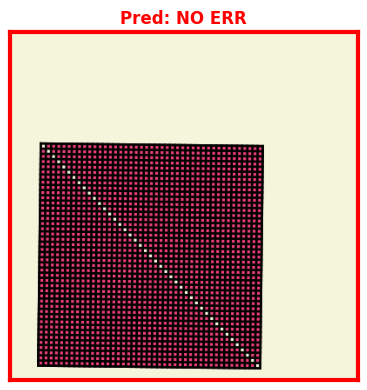


RESPONSE:
NO: The adjacency matrix sorts nodes from densest to sparsest. The transition from filled top-left to empty bottom-right visually proves incompleteness. 40 vertex pairs lack edges.

--------------------------------------------------------------------------------
ROW: NO
--------------------------------------------------------------------------------

[Exp1] Exp1: s_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Graph Completeness

Rules:
- YES if: Full adjacency matrix - ALL cells filled, all edges present between every pair of nodes. Only diagonal cells are empty (no self-loops).
- NO if: There are some missing edges (empty cells outside diagonal) in the adjacency matrix, showing it is not complete.

Question: Does this graph have Graph Completeness? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


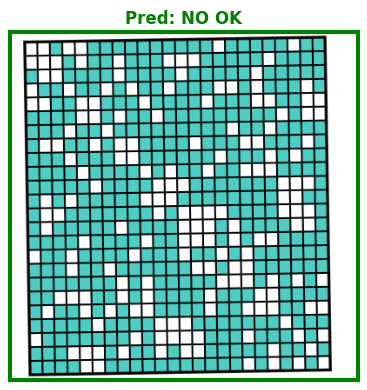


RESPONSE:
NO: Not complete. The graph has 230 of 300 possible edges (76.7% complete). The empty cells in the matrix show 70 missing edges.

[Exp2] Exp2: d_no
Correct: 150  |  Wrong: 0  |  Total: 150

PROMPT:
Property: Graph Completeness

Rules:
- YES if: Full adjacency matrix - ALL cells filled, all edges present between every pair of nodes. Only diagonal cells are empty (no self-loops).
- NO if: Nodes are sorted by degree (most connected to least). Matrix shows density gradient: dense/filled top-left region fading to sparse/empty bottom-right, proving that not all node pairs are connected.

Question: Does this graph have Graph Completeness? Answer YES or NO with detailed reasoning.

Format: YES/NO: [detailed reasoning explaining your observation]


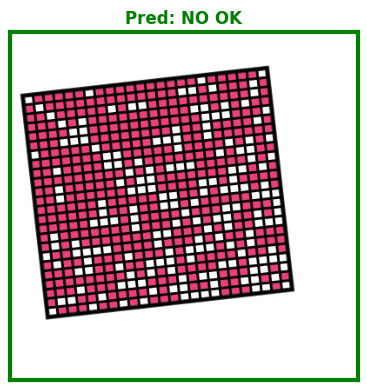


RESPONSE:
NO: The adjacency matrix sorts nodes from densest to sparsest. The transition from filled top-left to empty bottom-right visually proves incompleteness. 79 vertex pairs lack edges.


In [20]:
# ============================================================================
# STEP 16: Per-Property Results - 2x2 Matrix (Exp1 vs Exp2, YES vs NO)
# ============================================================================

def get_counts(df, prop, sample_type):
    """Get correct/wrong/total counts."""
    subset = df[(df['property'] == prop) & (df['sample_type'] == sample_type)]
    if len(subset) == 0:
        return 0, 0, 0
    expected = 1 if sample_type == 'yes' else 0
    correct = (subset['pred_label'] == expected).sum()
    wrong = len(subset) - correct
    return correct, wrong, len(subset)

def get_example(df, prop, sample_type, prefer_wrong=True):
    """Get example result."""
    subset = df[(df['property'] == prop) & (df['sample_type'] == sample_type)]
    if len(subset) == 0:
        return None, None
    expected = 1 if sample_type == 'yes' else 0
    wrong = subset[subset['pred_label'] != expected]
    correct = subset[subset['pred_label'] == expected]
    if prefer_wrong and len(wrong) > 0:
        return wrong.iloc[0].to_dict(), False
    elif len(correct) > 0:
        return correct.iloc[0].to_dict(), True
    elif len(wrong) > 0:
        return wrong.iloc[0].to_dict(), False
    return None, None

def show_cell(exp_name, row_type, df, sample_type, prop):
    """Display one cell: counts -> prompt -> image -> response."""
    c, w, t = get_counts(df, prop, sample_type)
    result, is_correct = get_example(df, prop, sample_type, prefer_wrong=True)

    status = 'OK' if is_correct else 'ERR'
    color = 'green' if is_correct else 'red'

    print(f"Correct: {c}  |  Wrong: {w}  |  Total: {t}")

    if result:
        print("\nPROMPT:")
        print(result.get('prompt', 'N/A'))

        if os.path.exists(result['image_path']):
            fig, ax = plt.subplots(figsize=(5, 4))
            ax.imshow(Image.open(result['image_path']))
            ax.set_title(f"Pred: {result['prediction']} {status}", color=color, fontweight='bold')
            for spine in ax.spines.values():
                spine.set_color(color)
                spine.set_linewidth(3)
            ax.set_xticks([])
            ax.set_yticks([])
            plt.tight_layout()
            plt.show()

        resp = result.get('response', 'N/A')
        resp = resp[:500] + '...' if len(resp) > 500 else resp
        print("\nRESPONSE:")
        print(resp)
    else:
        print('No sample available.')

def show_property_table(prop):
    """Show 2x2 matrix for one property."""
    print(f"\n{'=' * 80}")
    print(f"{prop.upper()}")
    print(f"{'=' * 80}")

    matrix = [
        [('YES', df_exp1, 'yes', 'Exp1 (s_no rules)'), ('YES', df_exp2, 'yes', 'Exp2 (d_no rules)')],
        [('NO',  df_exp1, 's_no', 'Exp1: s_no'),       ('NO',  df_exp2, 'd_no', 'Exp2: d_no')],
    ]

    for row_idx, row in enumerate(matrix):
        row_label = 'YES' if row_idx == 0 else 'NO'
        print(f"\n{'-' * 80}")
        print(f"ROW: {row_label}")
        print(f"{'-' * 80}")

        for col_idx, (rtype, df, stype, title) in enumerate(row):
            col_label = 'Exp1' if col_idx == 0 else 'Exp2'
            print(f"\n[{col_label}] {title}")
            show_cell(col_label, rtype, df, stype, prop)

for prop in config.ALL_PROPERTIES:
    show_property_table(prop)

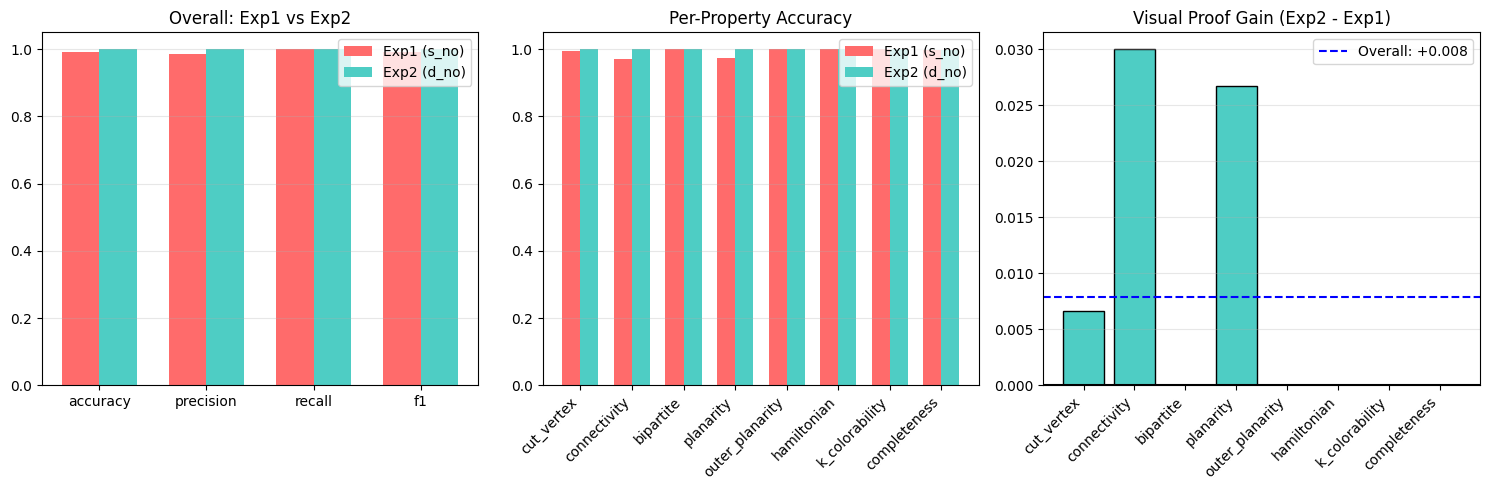

In [21]:
# ============================================================================
# STEP 17: Visualize Results (Exp1 vs Exp2)
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1: Overall comparison bar chart
ax1 = axes[0]
metrics_list = ['accuracy', 'precision', 'recall', 'f1']
x = np.arange(len(metrics_list))
width = 0.35
ax1.bar(x - width/2, [metrics_exp1[m] for m in metrics_list], width, label='Exp1 (s_no)', color='#FF6B6B')
ax1.bar(x + width/2, [metrics_exp2[m] for m in metrics_list], width, label='Exp2 (d_no)', color='#4ECDC4')
ax1.set_xticks(x)
ax1.set_xticklabels(metrics_list)
ax1.set_ylim(0, 1.05)
ax1.legend()
ax1.set_title('Overall: Exp1 vs Exp2')
ax1.grid(axis='y', alpha=0.3)

# 2: Per-property accuracy comparison
ax2 = axes[1]
props = list(per_prop_exp1.keys())
exp1_accs = [per_prop_exp1[p]['accuracy'] for p in props]
exp2_accs = [per_prop_exp2.get(p, {}).get('accuracy', 0) for p in props]
x = np.arange(len(props))
ax2.bar(x - width/2, exp1_accs, width, label='Exp1 (s_no)', color='#FF6B6B')
ax2.bar(x + width/2, exp2_accs, width, label='Exp2 (d_no)', color='#4ECDC4')
ax2.set_xticks(x)
ax2.set_xticklabels(props, rotation=45, ha='right')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.set_title('Per-Property Accuracy')
ax2.grid(axis='y', alpha=0.3)

# 3: Visual Proof Gain per property
ax3 = axes[2]
gains = [exp2_accs[i] - exp1_accs[i] for i in range(len(props))]
colors = ['#4ECDC4' if g >= 0 else '#FF6B6B' for g in gains]
ax3.bar(props, gains, color=colors, edgecolor='black')
ax3.axhline(y=0, color='black', linestyle='-')
ax3.axhline(y=visual_proof_gain, color='blue', linestyle='--', label=f'Overall: {visual_proof_gain:+.3f}')
ax3.set_xticklabels(props, rotation=45, ha='right')
ax3.legend()
ax3.set_title('Visual Proof Gain (Exp2 - Exp1)')
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(config.RESULTS_DIR, 'mllm_exp_comparison_finetune.png'), dpi=150, bbox_inches='tight')
plt.show()

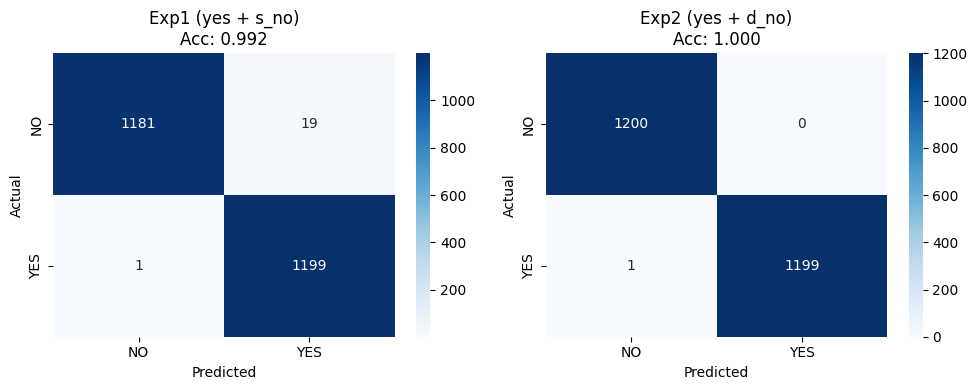

In [22]:
# ============================================================================
# STEP 18: Confusion Matrices (Exp1 vs Exp2)
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for idx, (df, name) in enumerate([(df_exp1_valid, 'Exp1 (yes + s_no)'), (df_exp2_valid, 'Exp2 (yes + d_no)')]):
    ax = axes[idx]
    cm = confusion_matrix(df['true_label'], df['pred_label'], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['NO', 'YES'], yticklabels=['NO', 'YES'])
    acc = accuracy_score(df['true_label'], df['pred_label'])
    ax.set_title(f'{name}\nAcc: {acc:.3f}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig(os.path.join(config.RESULTS_DIR, 'mllm_confusion_matrices_finetune.png'), dpi=150, bbox_inches='tight')
plt.show()

In [23]:
# ============================================================================
# STEP 19: Save Results
# ============================================================================
import os, json
os.makedirs(config.RESULTS_DIR, exist_ok=True)

final_results = {
    'model': config.MODEL_NAME,
    'exp1_s_no': {'metrics': metrics_exp1, 'per_property': per_prop_exp1},
    'exp2_d_no': {'metrics': metrics_exp2, 'per_property': per_prop_exp2},
    'visual_proof_gain': visual_proof_gain,
}

with open(os.path.join(config.RESULTS_DIR, 'mllm_finetune_results.json'), 'w', encoding='utf-8') as f:
    json.dump(final_results, f, indent=2)

pd.DataFrame(results_p1).to_csv(os.path.join(config.RESULTS_DIR, 'mllm_finetune_exp1_s_no.csv'), index=False)
pd.DataFrame(results_p2).to_csv(os.path.join(config.RESULTS_DIR, 'mllm_finetune_exp2_d_no.csv'), index=False)

print(f"Saved results to {config.RESULTS_DIR}/")

Saved results to ./mllm_results/


In [24]:
# ============================================================================
# STEP 20: Final Summary — Both Pipelines
# ============================================================================

print("=" * 70)
print("  MLLM FINE-TUNING COMPLETE — Qwen2.5-VL-3B-Instruct (QLoRA 4-bit)")
print("=" * 70)

for label, metrics, best_ep, best_loss in [
    ("Pipeline 1 — Same Layout  (yes vs s_no)", metrics_p1, best_epoch_p1, best_val_loss_p1),
    ("Pipeline 2 — Diff Layout  (yes vs d_no)", metrics_p2, best_epoch_p2, best_val_loss_p2),
]:
    print(f"\n{label}")
    print(f"  Best epoch      : {best_ep}")
    print(f"  Best val loss   : {best_loss:.6f}")
    print(f"  Test samples    : {metrics.get('n_samples', 'N/A')}")
    print(f"  Accuracy        : {metrics.get('accuracy',  0):.4f}")
    print(f"  Precision       : {metrics.get('precision', 0):.4f}")
    print(f"  Recall          : {metrics.get('recall',    0):.4f}")
    print(f"  F1 Score        : {metrics.get('f1',        0):.4f}")

print()
print(f"Checkpoints saved in : {config.CHECKPOINT_DIR_SNO}")
print(f"                       {config.CHECKPOINT_DIR_DNO}")
print(f"Results saved in     : {config.RESULTS_DIR}/")
print("=" * 70)


  MLLM FINE-TUNING COMPLETE — Qwen2.5-VL-3B-Instruct (QLoRA 4-bit)

Pipeline 1 — Same Layout  (yes vs s_no)
  Best epoch      : 3
  Best val loss   : 0.085790
  Test samples    : 2400
  Accuracy        : 0.9917
  Precision       : 0.9844
  Recall          : 0.9992
  F1 Score        : 0.9917

Pipeline 2 — Diff Layout  (yes vs d_no)
  Best epoch      : 3
  Best val loss   : 0.077652
  Test samples    : 2400
  Accuracy        : 0.9996
  Precision       : 1.0000
  Recall          : 0.9992
  F1 Score        : 0.9996

Checkpoints saved in : ./mllm_checkpoints/pipeline_sno
                       ./mllm_checkpoints/pipeline_dno
Results saved in     : ./mllm_results/
